In [1]:

# %% CELL 1: ENVIRONMENT DIAGNOSTICS

import sys
import platform
import subprocess
import importlib.metadata as metadata

print("=" * 60)
print("SYSTEM INFORMATION")
print("=" * 60)

print("Python:", sys.version)
print("Platform:", platform.platform())

print("\n" + "=" * 60)
print("PYTORCH AND CUDA")
print("=" * 60)

try:
    import torch

    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    print("PyTorch CUDA version:", torch.version.cuda)

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print("GPU count:", torch.cuda.device_count())

        props = torch.cuda.get_device_properties(0)
        print("GPU VRAM:", round(props.total_memory / 1024**3, 2), "GB")

        print("cuDNN:", torch.backends.cudnn.version())

except Exception as e:
    print("PyTorch diagnostic error:", repr(e))

print("\n" + "=" * 60)
print("INSTALLED LIBRARIES")
print("=" * 60)

packages = [
    "ultralytics",
    "torchvision",
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "opencv-python",
    "PyYAML",
    "scikit-learn"
]

for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

print("\n" + "=" * 60)
print("NVIDIA DRIVER")
print("=" * 60)

try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        timeout=15
    )
    print(result.stdout if result.returncode == 0 else result.stderr)
except Exception as e:
    print("nvidia-smi unavailable:", repr(e))


SYSTEM INFORMATION
Python: 3.11.3 (tags/v3.11.3:f3909b8, Apr  4 2023, 23:49:59) [MSC v.1934 64 bit (AMD64)]
Platform: Windows-10-10.0.26200-SP0

PYTORCH AND CUDA
PyTorch: 2.11.0+cu128
CUDA available: True
PyTorch CUDA version: 12.8
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
GPU count: 1
GPU VRAM: 7.93 GB
cuDNN: 91900

INSTALLED LIBRARIES
ultralytics: 8.4.190
torchvision: 0.26.0+cu128
numpy: 2.4.6
pandas: 3.1.0
matplotlib: 3.11.2
seaborn: 0.13.2
opencv-python: 5.0.0.93
PyYAML: 6.0.3
scikit-learn: 1.9.1

NVIDIA DRIVER
Tue Nov 10 14:30:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 616.92                 KMD Version: 616.92        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Co

In [3]:

# %% CELL 2: DATASET ARCHIVE DISCOVERY

from pathlib import Path
import zipfile

# Your actual project directory
PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

# Dataset archives are directly inside the project folder
RAW_DIR = PROJECT_DIR

# Expected dataset formats
DATASET_FILES = {
    "YOLOv8": "Fault_Detection_Model.v2i.yolov8.zip",
    "YOLOv11": "Fault_Detection_Model.v2i.yolov11.zip",
    "YOLOv12": "Fault_Detection_Model.v2i.yolov12.zip",
    "YOLOv26": "Fault_Detection_Model.v2i.yolo26.zip",
}

print("=" * 65)
print("OBJECT DETECTION PROJECT - DATASET DISCOVERY")
print("=" * 65)

print(f"\nProject directory: {PROJECT_DIR}")

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Project directory does not exist: {PROJECT_DIR}"
    )

DATASET_PATHS = {}

for model_name, filename in DATASET_FILES.items():

    archive_path = RAW_DIR / filename

    print(f"\nChecking {model_name}...")

    if not archive_path.exists():
        print(f"[MISSING] {filename}")
        continue

    # Verify ZIP archive integrity
    try:
        with zipfile.ZipFile(archive_path, "r") as archive:
            bad_file = archive.testzip()

            if bad_file is not None:
                print(f"[CORRUPTED] {bad_file}")
                continue

        size_mb = archive_path.stat().st_size / (1024 ** 2)

        DATASET_PATHS[model_name] = archive_path

        print(f"[VALID] {filename}")
        print(f"Size: {size_mb:.2f} MB")

    except zipfile.BadZipFile:
        print(f"[INVALID ZIP] {filename}")

print("\n" + "=" * 65)
print("DISCOVERY SUMMARY")
print("=" * 65)

print(f"Valid archives: {len(DATASET_PATHS)}/4")

for model_name, path in DATASET_PATHS.items():
    print(f"{model_name}: {path.name}")

if len(DATASET_PATHS) != 4:
    raise RuntimeError(
        "Not all four dataset archives were verified. "
        "Check the filenames and project directory."
    )

print("\nSUCCESS: All four dataset archives are accessible.")


OBJECT DETECTION PROJECT - DATASET DISCOVERY

Project directory: G:\Code\object_detection_Project

Checking YOLOv8...
[VALID] Fault_Detection_Model.v2i.yolov8.zip
Size: 25.31 MB

Checking YOLOv11...
[VALID] Fault_Detection_Model.v2i.yolov11.zip
Size: 25.31 MB

Checking YOLOv12...
[VALID] Fault_Detection_Model.v2i.yolov12.zip
Size: 25.31 MB

Checking YOLOv26...
[VALID] Fault_Detection_Model.v2i.yolo26.zip
Size: 25.31 MB

DISCOVERY SUMMARY
Valid archives: 4/4
YOLOv8: Fault_Detection_Model.v2i.yolov8.zip
YOLOv11: Fault_Detection_Model.v2i.yolov11.zip
YOLOv12: Fault_Detection_Model.v2i.yolov12.zip
YOLOv26: Fault_Detection_Model.v2i.yolo26.zip

SUCCESS: All four dataset archives are accessible.


In [4]:

# %% CELL 3: VERIFY AND EXTRACT CANONICAL DATASET

from pathlib import Path, PurePosixPath
import zipfile
import hashlib
import json

# --------------------------------------------------
# 1. PROJECT CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

DATA_DIR = PROJECT_DIR / "data"
CANONICAL_DIR = DATA_DIR / "canonical"

DATASET_FILES = {
    "YOLOv8": "Fault_Detection_Model.v2i.yolov8.zip",
    "YOLOv11": "Fault_Detection_Model.v2i.yolov11.zip",
    "YOLOv12": "Fault_Detection_Model.v2i.yolov12.zip",
    "YOLOv26": "Fault_Detection_Model.v2i.yolo26.zip",
}

# --------------------------------------------------
# 2. HASH FUNCTION
# --------------------------------------------------

def calculate_hash(content):
    return hashlib.sha256(content).hexdigest()


def get_dataset_hashes(zip_path):
    """
    Hash all image and label files inside an archive.
    Ignore README and YAML metadata.
    """

    hashes = {}

    with zipfile.ZipFile(zip_path, "r") as archive:

        for info in archive.infolist():

            if info.is_dir():
                continue

            name = info.filename.replace("\\", "/")
            parts = PurePosixPath(name).parts

            if (
                len(parts) >= 3
                and parts[0] in ("train", "valid", "test")
                and parts[1] in ("images", "labels")
            ):

                hashes[name] = calculate_hash(
                    archive.read(info)
                )

    return hashes


# --------------------------------------------------
# 3. COMPARE ALL FOUR DATASETS
# --------------------------------------------------

print("=" * 65)
print("COMPARING FOUR DATASET EXPORTS")
print("=" * 65)

reference_hashes = None

for model_name, filename in DATASET_FILES.items():

    archive_path = PROJECT_DIR / filename

    if not archive_path.exists():
        raise FileNotFoundError(archive_path)

    current_hashes = get_dataset_hashes(archive_path)

    print(f"\n{model_name}")
    print("Files:", len(current_hashes))

    if reference_hashes is None:
        reference_hashes = current_hashes
        print("Reference dataset established.")

    elif current_hashes == reference_hashes:
        print("[MATCH] Image and annotation contents identical.")

    else:
        missing = set(reference_hashes) - set(current_hashes)
        extra = set(current_hashes) - set(reference_hashes)

        changed = [
            name for name in set(reference_hashes)
            & set(current_hashes)
            if reference_hashes[name] != current_hashes[name]
        ]

        raise RuntimeError(
            f"Dataset mismatch in {model_name}.\n"
            f"Missing: {len(missing)}\n"
            f"Extra: {len(extra)}\n"
            f"Changed: {len(changed)}"
        )

print("\nAll four exports contain identical image/label files.")


# --------------------------------------------------
# 4. SAFE EXTRACTION
# --------------------------------------------------

if CANONICAL_DIR.exists() and any(CANONICAL_DIR.iterdir()):
    raise FileExistsError(
        f"{CANONICAL_DIR} already contains files. "
        "Use another empty destination or inspect the existing data."
    )

CANONICAL_DIR.mkdir(parents=True, exist_ok=True)

SOURCE_ZIP = PROJECT_DIR / DATASET_FILES["YOLOv8"]

print("\n" + "=" * 65)
print("EXTRACTING CANONICAL DATASET")
print("=" * 65)

with zipfile.ZipFile(SOURCE_ZIP, "r") as archive:

    for info in archive.infolist():

        if info.is_dir():
            continue

        name = info.filename.replace("\\", "/")
        relative_path = PurePosixPath(name)

        # Reject unsafe archive paths
        if (
            relative_path.is_absolute()
            or ".." in relative_path.parts
            or not relative_path.parts
        ):
            raise ValueError(f"Unsafe ZIP path: {name}")

        # Extract only images and labels
        if (
            len(relative_path.parts) >= 3
            and relative_path.parts[0] in ("train", "valid", "test")
            and relative_path.parts[1] in ("images", "labels")
        ):

            destination = CANONICAL_DIR.joinpath(
                *relative_path.parts
            )

            destination.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            destination.write_bytes(archive.read(info))


# --------------------------------------------------
# 5. CREATE CLEAN YOLO DATA YAML
# --------------------------------------------------

yaml_content = """\
path: .
train: train/images
val: valid/images
test: test/images

nc: 2
names:
  0: Good
  1: Miss_Print
"""

yaml_path = CANONICAL_DIR / "data.yaml"
yaml_path.write_text(yaml_content, encoding="utf-8")


# --------------------------------------------------
# 6. VERIFY EXTRACTED COUNTS
# --------------------------------------------------

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("\n" + "=" * 65)
print("EXTRACTION SUMMARY")
print("=" * 65)

for split in ("train", "valid", "test"):

    image_dir = CANONICAL_DIR / split / "images"
    label_dir = CANONICAL_DIR / split / "labels"

    image_count = sum(
        1 for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    label_count = sum(
        1 for p in label_dir.glob("*.txt")
        if p.is_file()
    )

    print(
        f"{split.upper():<8} "
        f"Images: {image_count:<5} "
        f"Labels: {label_count}"
    )

    if image_count != label_count:
        raise RuntimeError(
            f"Image/label count mismatch in {split}"
        )

# --------------------------------------------------
# 7. SAVE PROVENANCE INFORMATION
# --------------------------------------------------

metadata = {
    "source_archive": SOURCE_ZIP.name,
    "verified_archives": list(DATASET_FILES.keys()),
    "dataset_files": len(reference_hashes),
    "dataset_hash_algorithm": "SHA-256",
    "classes": ["Good", "Miss_Print"],
    "dataset_path": str(CANONICAL_DIR),
}

metadata_path = DATA_DIR / "dataset_provenance.json"

DATA_DIR.mkdir(parents=True, exist_ok=True)

metadata_path.write_text(
    json.dumps(metadata, indent=4),
    encoding="utf-8"
)

print("\nSUCCESS: Canonical dataset prepared.")
print("Dataset YAML:", yaml_path)
print("Provenance:", metadata_path)
print("Dataset directory:", CANONICAL_DIR)


COMPARING FOUR DATASET EXPORTS

YOLOv8
Files: 1060
Reference dataset established.

YOLOv11
Files: 1060
[MATCH] Image and annotation contents identical.

YOLOv12
Files: 1060
[MATCH] Image and annotation contents identical.

YOLOv26
Files: 1060
[MATCH] Image and annotation contents identical.

All four exports contain identical image/label files.

EXTRACTING CANONICAL DATASET

EXTRACTION SUMMARY
TRAIN    Images: 489   Labels: 489
VALID    Images: 20    Labels: 20
TEST     Images: 21    Labels: 21

SUCCESS: Canonical dataset prepared.
Dataset YAML: G:\Code\object_detection_Project\data\canonical\data.yaml
Provenance: G:\Code\object_detection_Project\data\dataset_provenance.json
Dataset directory: G:\Code\object_detection_Project\data\canonical


In [5]:

# %% CELL 4: ANNOTATION AUDIT AND POLYGON-TO-BOX CONVERSION

from pathlib import Path
import shutil
import cv2
import numpy as np
import pandas as pd
import yaml

# --------------------------------------------------
# 1. PATHS
# --------------------------------------------------

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

SOURCE_DIR = PROJECT_DIR / "data" / "canonical"
OUTPUT_DIR = PROJECT_DIR / "data" / "detection_ready"

SPLITS = ["train", "valid", "test"]

CLASS_NAMES = {
    0: "Good",
    1: "Miss_Print"
}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Never overwrite an existing processed dataset.
if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"{OUTPUT_DIR} already exists. "
        "Inspect it or choose a new output directory."
    )

OUTPUT_DIR.mkdir(parents=True)

# --------------------------------------------------
# 2. VALIDATION FUNCTION
# --------------------------------------------------

def parse_annotation_line(line, image_name):
    """
    Validate a YOLO box or polygon annotation.

    Standard box:
    class x_center y_center width height

    Polygon:
    class x1 y1 x2 y2 ... xn yn

    Returns:
        normalized YOLO bounding-box annotation.
    """

    values = line.split()

    if len(values) < 5:
        raise ValueError(
            f"Too few coordinates: {image_name}: {line}"
        )

    if (len(values) - 1) % 2 != 0 and len(values) != 5:
        raise ValueError(
            f"Invalid polygon coordinate count: {image_name}"
        )

    try:
        numeric = np.asarray(values, dtype=np.float64)
    except ValueError:
        raise ValueError(
            f"Non-numeric annotation: {image_name}"
        )

    class_value = numeric[0]

    if not np.isfinite(numeric).all():
        raise ValueError(
            f"NaN or Inf detected: {image_name}"
        )

    if class_value not in CLASS_NAMES:
        raise ValueError(
            f"Unknown class ID {class_value}: {image_name}"
        )

    class_id = int(class_value)

    coords = numeric[1:]

    if np.any(coords < 0) or np.any(coords > 1):
        raise ValueError(
            f"Coordinates outside [0,1]: {image_name}"
        )

    # Standard YOLO bounding box
    if len(numeric) == 5:

        xc, yc, width, height = coords

        if width <= 0 or height <= 0:
            raise ValueError(
                f"Invalid bounding-box dimensions: {image_name}"
            )

        if (
            xc - width / 2 < -1e-6
            or yc - height / 2 < -1e-6
            or xc + width / 2 > 1 + 1e-6
            or yc + height / 2 > 1 + 1e-6
        ):
            raise ValueError(
                f"Bounding box exceeds image boundaries: {image_name}"
            )

        return (
            f"{class_id} {xc:.8f} {yc:.8f} "
            f"{width:.8f} {height:.8f}",
            "bbox"
        )

    # Polygon conversion
    if len(coords) < 6 or len(coords) % 2 != 0:
        raise ValueError(
            f"Invalid polygon: {image_name}"
        )

    points = coords.reshape(-1, 2)

    x_min, y_min = points.min(axis=0)
    x_max, y_max = points.max(axis=0)

    width = x_max - x_min
    height = y_max - y_min

    if width <= 0 or height <= 0:
        raise ValueError(
            f"Degenerate polygon: {image_name}"
        )

    xc = (x_min + x_max) / 2
    yc = (y_min + y_max) / 2

    converted = (
        f"{class_id} {xc:.8f} {yc:.8f} "
        f"{width:.8f} {height:.8f}"
    )

    return converted, "polygon"


# --------------------------------------------------
# 3. PROCESS EACH DATASET SPLIT
# --------------------------------------------------

audit_records = []

total_bbox = 0
total_polygon = 0
total_objects = 0

class_distribution = {
    split: {class_id: 0 for class_id in CLASS_NAMES}
    for split in SPLITS
}

print("=" * 65)
print("ANNOTATION AUDIT AND CONVERSION")
print("=" * 65)

for split in SPLITS:

    source_images = SOURCE_DIR / split / "images"
    source_labels = SOURCE_DIR / split / "labels"

    output_images = OUTPUT_DIR / split / "images"
    output_labels = OUTPUT_DIR / split / "labels"

    output_images.mkdir(parents=True)
    output_labels.mkdir(parents=True)

    if not source_images.exists() or not source_labels.exists():
        raise FileNotFoundError(
            f"Missing images or labels directory: {split}"
        )

    images = sorted(
        p for p in source_images.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    image_stems = {p.stem for p in images}

    label_files = {
        p.stem: p
        for p in source_labels.glob("*.txt")
    }

    if image_stems != set(label_files):
        missing_labels = image_stems - set(label_files)
        missing_images = set(label_files) - image_stems

        raise RuntimeError(
            f"Image/label mismatch in {split}.\n"
            f"Missing labels: {missing_labels}\n"
            f"Missing images: {missing_images}"
        )

    split_bbox = 0
    split_polygon = 0
    split_objects = 0

    for image_path in images:

        # Verify image readability
        image = cv2.imread(str(image_path))

        if image is None:
            raise RuntimeError(
                f"Corrupted or unreadable image: {image_path}"
            )

        height, width = image.shape[:2]

        if height <= 0 or width <= 0:
            raise RuntimeError(
                f"Invalid image dimensions: {image_path}"
            )

        label_path = label_files[image_path.stem]

        converted_lines = []

        text = label_path.read_text(
            encoding="utf-8-sig"
        )

        for line_number, line in enumerate(
            text.splitlines(), start=1
        ):

            if not line.strip():
                continue

            try:
                converted, annotation_type = parse_annotation_line(
                    line, image_path.name
                )
            except Exception as exc:
                raise RuntimeError(
                    f"Annotation error in {label_path}, "
                    f"line {line_number}: {exc}"
                ) from exc

            converted_lines.append(converted)

            class_id = int(converted.split()[0])

            class_distribution[split][class_id] += 1
            split_objects += 1
            total_objects += 1

            if annotation_type == "bbox":
                split_bbox += 1
                total_bbox += 1
            else:
                split_polygon += 1
                total_polygon += 1

        # Copy original image without modification
        shutil.copy2(
            image_path,
            output_images / image_path.name
        )

        # Save converted YOLO detection labels
        (output_labels / f"{image_path.stem}.txt").write_text(
            "\n".join(converted_lines) + (
                "\n" if converted_lines else ""
            ),
            encoding="utf-8"
        )

    audit_records.append({
        "split": split,
        "images": len(images),
        "bounding_boxes": split_bbox,
        "converted_polygons": split_polygon,
        "total_objects": split_objects
    })

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Original boxes:", split_bbox)
    print("Converted polygons:", split_polygon)
    print("Total objects:", split_objects)


# --------------------------------------------------
# 4. CREATE DETECTION DATA YAML
# --------------------------------------------------

yaml_config = {
    "path": ".",
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 2,
    "names": {
        0: "Good",
        1: "Miss_Print"
    }
}

yaml_path = OUTPUT_DIR / "data.yaml"

with open(yaml_path, "w", encoding="utf-8") as file:
    yaml.safe_dump(
        yaml_config,
        file,
        sort_keys=False,
        allow_unicode=True
    )


# --------------------------------------------------
# 5. SAVE AUDIT REPORTS
# --------------------------------------------------

audit_df = pd.DataFrame(audit_records)

audit_df.to_csv(
    PROJECT_DIR / "data" / "annotation_audit.csv",
    index=False
)

class_rows = []

for split in SPLITS:
    for class_id, class_name in CLASS_NAMES.items():

        class_rows.append({
            "split": split,
            "class_id": class_id,
            "class_name": class_name,
            "instances": class_distribution[split][class_id]
        })

class_df = pd.DataFrame(class_rows)

class_df.to_csv(
    PROJECT_DIR / "data" / "class_distribution.csv",
    index=False
)


# --------------------------------------------------
# 6. FINAL SUMMARY
# --------------------------------------------------

print("\n" + "=" * 65)
print("FINAL ANNOTATION SUMMARY")
print("=" * 65)

print("Original bounding boxes:", total_bbox)
print("Converted polygons:", total_polygon)
print("Total objects:", total_objects)

print("\nCLASS DISTRIBUTION")
print(class_df.pivot(
    index="split",
    columns="class_name",
    values="instances"
))

print("\nSUCCESS: Detection-ready dataset generated.")
print("Dataset:", OUTPUT_DIR)
print("YAML:", yaml_path)
print("Audit report:", PROJECT_DIR / "data" / "annotation_audit.csv")


ANNOTATION AUDIT AND CONVERSION

TRAIN
Images: 489
Original boxes: 671
Converted polygons: 6
Total objects: 677

VALID
Images: 20
Original boxes: 27
Converted polygons: 0
Total objects: 27

TEST
Images: 21
Original boxes: 29
Converted polygons: 0
Total objects: 29

FINAL ANNOTATION SUMMARY
Original bounding boxes: 727
Converted polygons: 6
Total objects: 733

CLASS DISTRIBUTION
class_name  Good  Miss_Print
split                       
test          14          15
train        371         306
valid         15          12

SUCCESS: Detection-ready dataset generated.
Dataset: G:\Code\object_detection_Project\data\detection_ready
YAML: G:\Code\object_detection_Project\data\detection_ready\data.yaml
Audit report: G:\Code\object_detection_Project\data\annotation_audit.csv


DATASET STATISTICS
Images: 530
Objects: 733

Objects per split:
split
test      29
train    677
valid     27
dtype: int64

Objects per class:
class_name
Good          400
Miss_Print    333
dtype: int64

Image dimensions:
width  height
640    640       530
dtype: int64


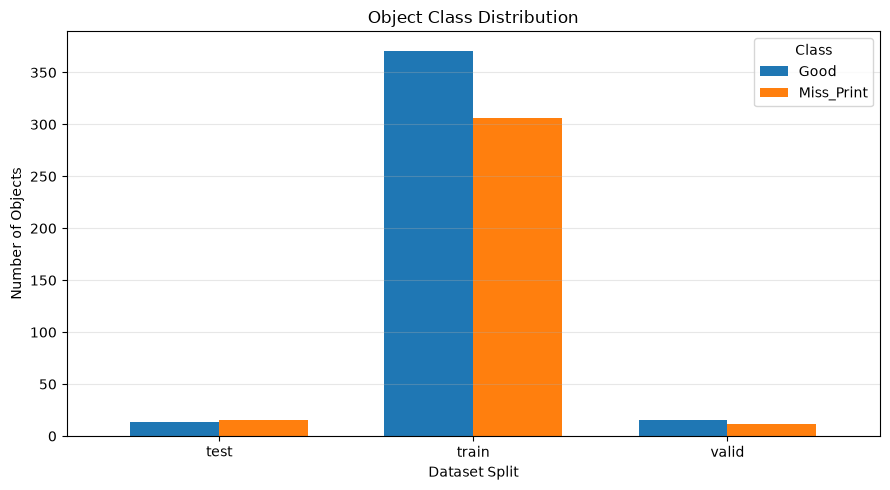

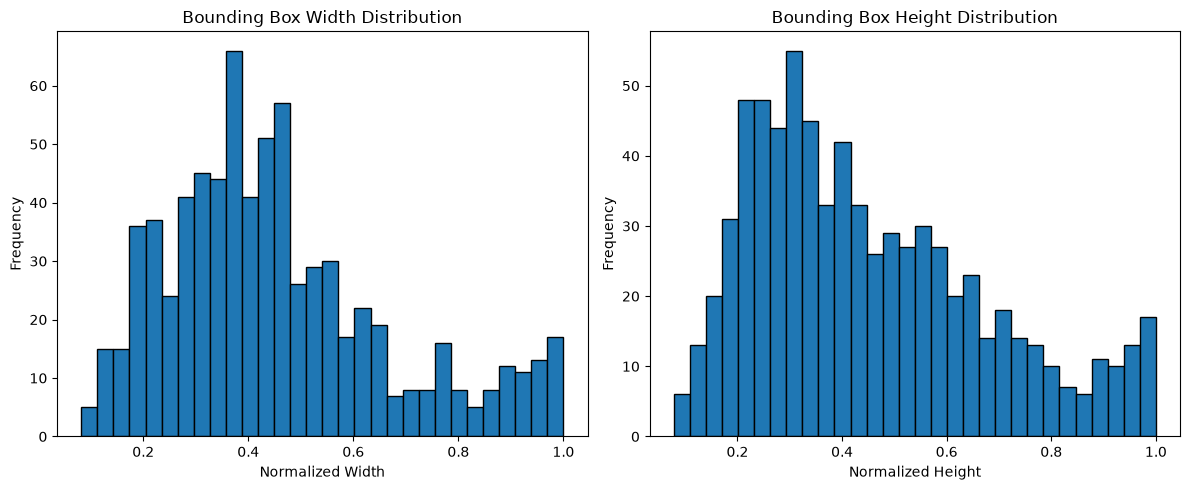

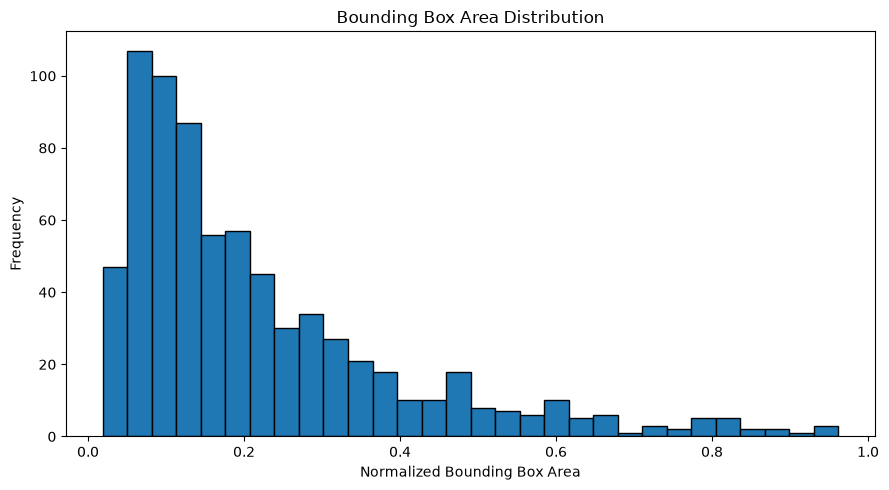


Most common image dimensions:
width  height
640    640       530
dtype: int64


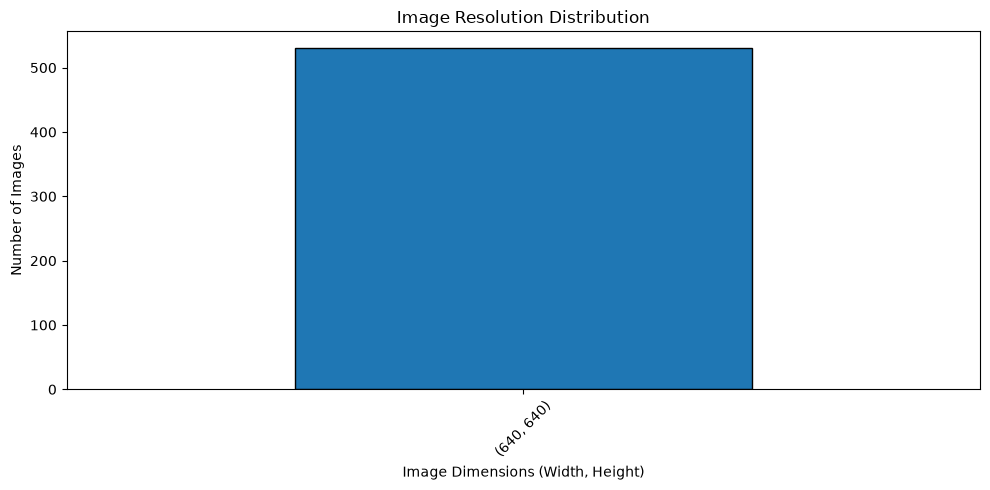

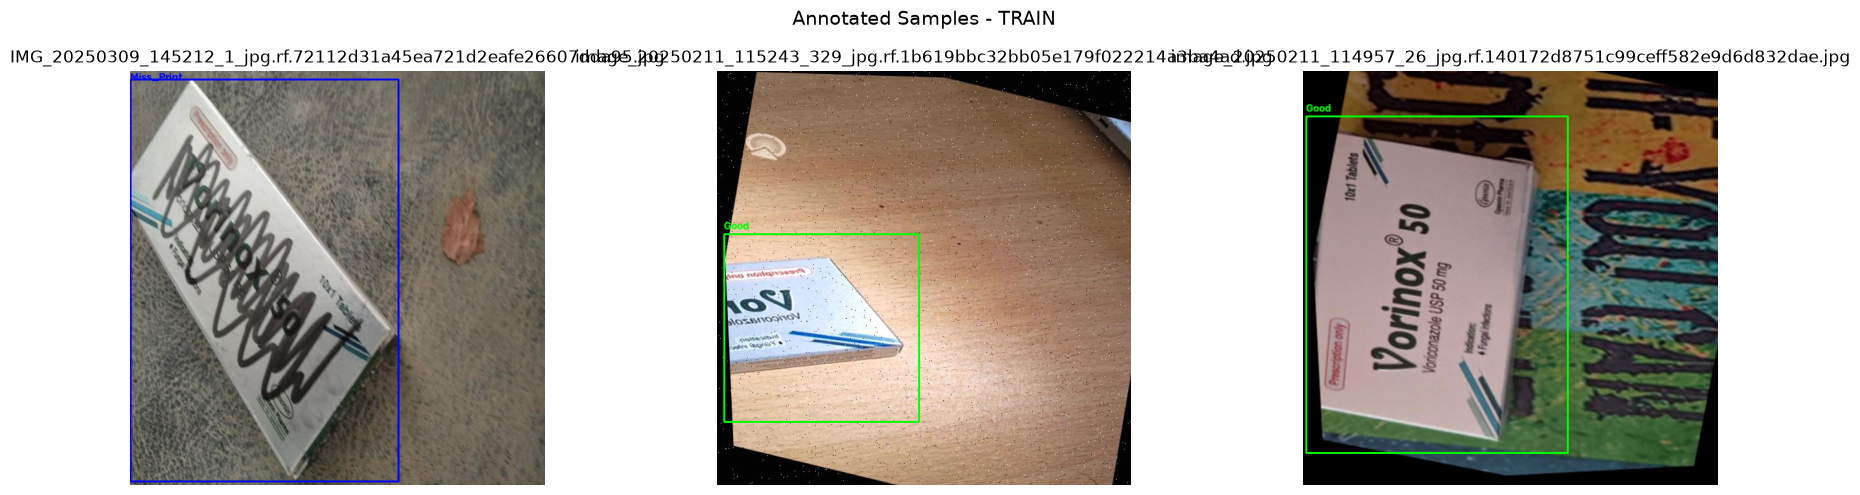

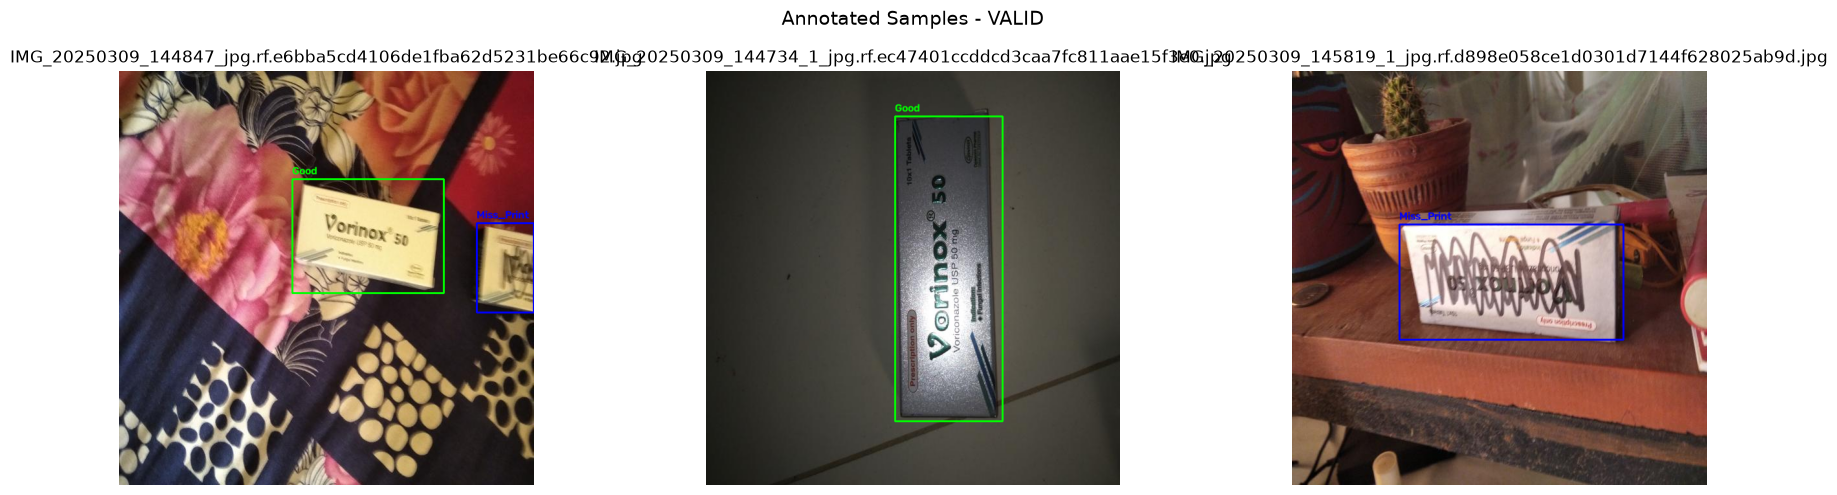

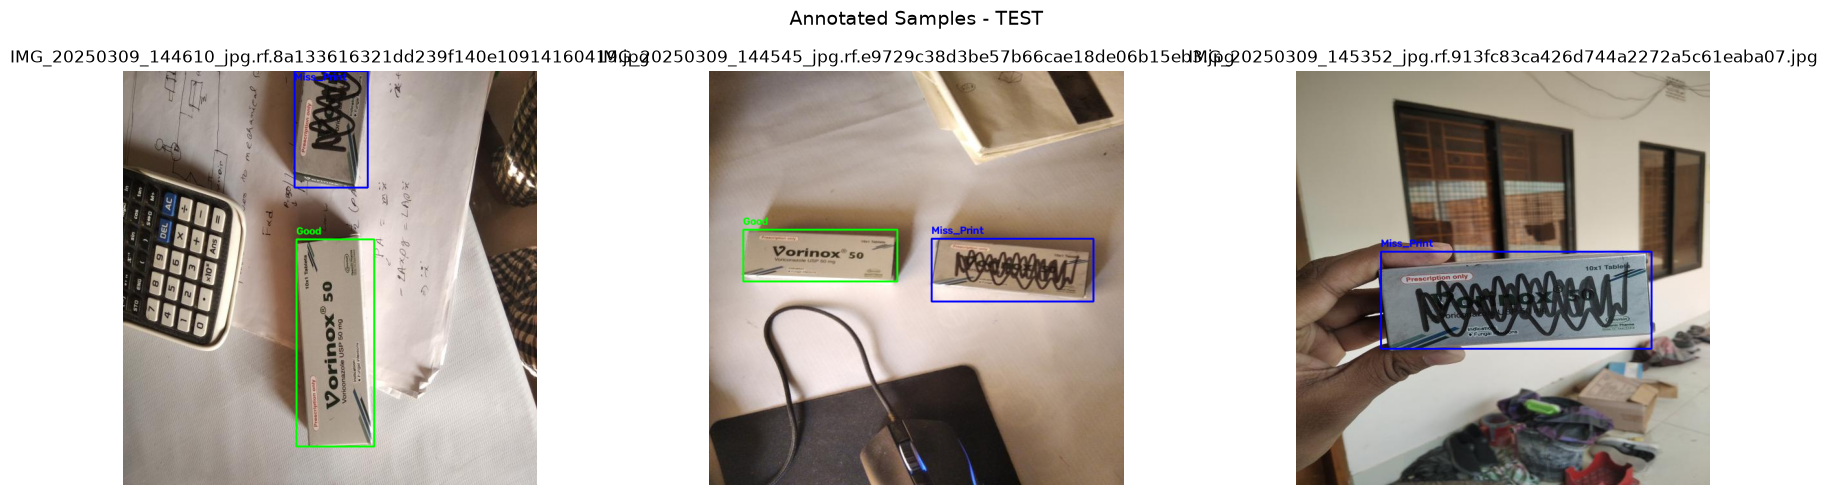


EDA COMPLETED
Reports: G:\Code\object_detection_Project\reports
Figures: G:\Code\object_detection_Project\reports\figures


In [6]:

# %% CELL 5: DATASET EDA AND VISUALIZATION

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")
DATASET_DIR = PROJECT_DIR / "data" / "detection_ready"

REPORT_DIR = PROJECT_DIR / "reports"
FIGURE_DIR = REPORT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "valid", "test"]

CLASS_NAMES = {
    0: "Good",
    1: "Miss_Print"
}

COLORS = {
    0: (0, 255, 0),
    1: (0, 0, 255)
}

random.seed(42)
np.random.seed(42)

# --------------------------------------------------
# 2. COLLECT DATASET STATISTICS
# --------------------------------------------------

box_records = []
image_records = []

for split in SPLITS:

    image_dir = DATASET_DIR / split / "images"
    label_dir = DATASET_DIR / split / "labels"

    for image_path in sorted(image_dir.iterdir()):

        if image_path.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            continue

        image = cv2.imread(str(image_path))

        if image is None:
            raise RuntimeError(f"Cannot read {image_path}")

        img_h, img_w = image.shape[:2]

        image_records.append({
            "split": split,
            "image": image_path.name,
            "width": img_w,
            "height": img_h
        })

        label_path = label_dir / f"{image_path.stem}.txt"

        lines = label_path.read_text(
            encoding="utf-8"
        ).splitlines()

        for line in lines:

            if not line.strip():
                continue

            values = np.array(
                line.split(), dtype=float
            )

            class_id = int(values[0])

            xc, yc, bw, bh = values[1:5]

            box_records.append({
                "split": split,
                "image": image_path.name,
                "class_id": class_id,
                "class_name": CLASS_NAMES[class_id],
                "image_width": img_w,
                "image_height": img_h,
                "box_width_norm": bw,
                "box_height_norm": bh,
                "box_area_norm": bw * bh,
                "box_aspect_ratio": bw / bh
            })

boxes_df = pd.DataFrame(box_records)
images_df = pd.DataFrame(image_records)

print("=" * 65)
print("DATASET STATISTICS")
print("=" * 65)

print("Images:", len(images_df))
print("Objects:", len(boxes_df))

print("\nObjects per split:")
print(boxes_df.groupby("split").size())

print("\nObjects per class:")
print(boxes_df.groupby("class_name").size())

print("\nImage dimensions:")
print(images_df.groupby(
    ["width", "height"]
).size())

# Save statistics
boxes_df.to_csv(
    REPORT_DIR / "bounding_box_statistics.csv",
    index=False
)

images_df.to_csv(
    REPORT_DIR / "image_statistics.csv",
    index=False
)


# --------------------------------------------------
# 3. CLASS DISTRIBUTION
# --------------------------------------------------

class_counts = boxes_df.groupby(
    ["split", "class_name"]
).size().unstack(fill_value=0)

ax = class_counts.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

ax.set_title("Object Class Distribution")
ax.set_xlabel("Dataset Split")
ax.set_ylabel("Number of Objects")
ax.legend(title="Class")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "01_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# 4. BOUNDING BOX WIDTH AND HEIGHT
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(
    boxes_df["box_width_norm"],
    bins=30,
    edgecolor="black"
)

axes[0].set_title("Bounding Box Width Distribution")
axes[0].set_xlabel("Normalized Width")
axes[0].set_ylabel("Frequency")

axes[1].hist(
    boxes_df["box_height_norm"],
    bins=30,
    edgecolor="black"
)

axes[1].set_title("Bounding Box Height Distribution")
axes[1].set_xlabel("Normalized Height")
axes[1].set_ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "02_bbox_dimensions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# 5. BOUNDING BOX AREA DISTRIBUTION
# --------------------------------------------------

plt.figure(figsize=(9, 5))

plt.hist(
    boxes_df["box_area_norm"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Normalized Bounding Box Area")
plt.ylabel("Frequency")
plt.title("Bounding Box Area Distribution")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "03_bbox_area.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# 6. IMAGE DIMENSION DISTRIBUTION
# --------------------------------------------------

dimension_counts = images_df.groupby(
    ["width", "height"]
).size().sort_values(ascending=False)

print("\nMost common image dimensions:")
print(dimension_counts.head(10))

plt.figure(figsize=(10, 5))

dimension_counts.head(10).plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Image Resolution Distribution")
plt.xlabel("Image Dimensions (Width, Height)")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "04_image_resolutions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# 7. ANNOTATED IMAGE VISUALIZATION
# --------------------------------------------------

def visualize_samples(split, samples=3):

    image_dir = DATASET_DIR / split / "images"
    label_dir = DATASET_DIR / split / "labels"

    image_files = sorted([
        p for p in image_dir.iterdir()
        if p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }
    ])

    selected = random.sample(
        image_files,
        min(samples, len(image_files))
    )

    fig, axes = plt.subplots(
        1,
        len(selected),
        figsize=(6 * len(selected), 5)
    )

    if len(selected) == 1:
        axes = [axes]

    for ax, image_path in zip(axes, selected):

        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(
            image, cv2.COLOR_BGR2RGB
        )

        h, w = image.shape[:2]

        label_path = label_dir / f"{image_path.stem}.txt"

        for line in label_path.read_text(
            encoding="utf-8"
        ).splitlines():

            if not line.strip():
                continue

            values = np.array(
                line.split(), dtype=float
            )

            class_id = int(values[0])
            xc, yc, bw, bh = values[1:5]

            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            color = COLORS[class_id]

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                color,
                2
            )

            cv2.putText(
                image,
                CLASS_NAMES[class_id],
                (x1, max(15, y1 - 7)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                color,
                2
            )

        ax.imshow(image)
        ax.set_title(image_path.name)
        ax.axis("off")

    plt.suptitle(
        f"Annotated Samples - {split.upper()}",
        fontsize=14
    )

    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"05_samples_{split}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


for split in SPLITS:
    visualize_samples(split, samples=3)


print("\n" + "=" * 65)
print("EDA COMPLETED")
print("=" * 65)

print("Reports:", REPORT_DIR)
print("Figures:", FIGURE_DIR)


In [7]:

# %% CELL 6: YOLO SMALL MODEL COMPATIBILITY CHECK

from pathlib import Path
from ultralytics import YOLO
import torch
import gc

# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

DATASET_YAML = (
    PROJECT_DIR / "data" / "detection_ready" / "data.yaml"
)

MODEL_CONFIG = {
    "YOLOv8": "yolov8s.pt",
    "YOLO11": "yolo11s.pt",
    "YOLO12": "yolo12s.pt",
    "YOLO26": "yolo26s.pt"
}

assert DATASET_YAML.exists(), "Dataset YAML not found."

print("=" * 65)
print("YOLO SMALL MODEL COMPATIBILITY TEST")
print("=" * 65)

print("Ultralytics:", __import__("ultralytics").__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is unavailable.")

results = []

for model_name, checkpoint in MODEL_CONFIG.items():

    print(f"\nTesting {model_name}: {checkpoint}")

    try:
        model = YOLO(checkpoint)

        # Verify object detection task
        if model.task != "detect":
            raise RuntimeError(
                f"Unexpected task: {model.task}"
            )

        parameter_count = sum(
            p.numel() for p in model.model.parameters()
        )

        results.append({
            "Model": model_name,
            "Checkpoint": checkpoint,
            "Task": model.task,
            "Parameters (M)": round(
                parameter_count / 1e6, 3
            ),
            "Status": "READY"
        })

        print("Status: READY")
        print("Task:", model.task)
        print(
            "Parameters:",
            f"{parameter_count / 1e6:.3f} Million"
        )

        del model
        gc.collect()
        torch.cuda.empty_cache()

    except Exception as e:

        results.append({
            "Model": model_name,
            "Checkpoint": checkpoint,
            "Task": "Unknown",
            "Parameters (M)": None,
            "Status": f"FAILED: {str(e)[:150]}"
        })

        print("FAILED:", repr(e))

print("\n" + "=" * 65)
print("COMPATIBILITY SUMMARY")
print("=" * 65)

import pandas as pd

compatibility_df = pd.DataFrame(results)

print(compatibility_df.to_string(index=False))

compatibility_df.to_csv(
    PROJECT_DIR / "reports" / "yolo_compatibility.csv",
    index=False
)

if not all(r["Status"] == "READY" for r in results):
    raise RuntimeError(
        "Some YOLO checkpoints failed. Resolve these before training."
    )

print("\nSUCCESS: All four small YOLO models are ready.")


YOLO SMALL MODEL COMPATIBILITY TEST
Ultralytics: 8.4.190
PyTorch: 2.11.0+cu128
CUDA: True

Testing YOLOv8: yolov8s.pt
Status: READY
Task: detect
Parameters: 11.167 Million

Testing YOLO11: yolo11s.pt
Status: READY
Task: detect
Parameters: 9.459 Million

Testing YOLO12: yolo12s.pt
Status: READY
Task: detect
Parameters: 9.286 Million

Testing YOLO26: yolo26s.pt
Status: READY
Task: detect
Parameters: 10.010 Million

COMPATIBILITY SUMMARY
 Model Checkpoint   Task  Parameters (M) Status
YOLOv8 yolov8s.pt detect          11.167  READY
YOLO11 yolo11s.pt detect           9.459  READY
YOLO12 yolo12s.pt detect           9.286  READY
YOLO26 yolo26s.pt detect          10.010  READY

SUCCESS: All four small YOLO models are ready.


In [9]:

# %% CELL 7A: FIX ULTRALYTICS DATASET PATH

from pathlib import Path
import yaml

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

DATASET_DIR = (
    PROJECT_DIR / "data" / "detection_ready"
)

DATA_YAML = DATASET_DIR / "data.yaml"

# --------------------------------------------------
# 1. VERIFY ACTUAL DIRECTORIES
# --------------------------------------------------

required_dirs = [
    DATASET_DIR / "train" / "images",
    DATASET_DIR / "train" / "labels",
    DATASET_DIR / "valid" / "images",
    DATASET_DIR / "valid" / "labels",
    DATASET_DIR / "test" / "images",
    DATASET_DIR / "test" / "labels",
]

print("=" * 60)
print("DATASET DIRECTORY VERIFICATION")
print("=" * 60)

for directory in required_dirs:

    if not directory.exists():
        raise FileNotFoundError(
            f"Missing directory: {directory}"
        )

    print("[FOUND]", directory)

# --------------------------------------------------
# 2. CREATE ABSOLUTE-PATH YAML
# --------------------------------------------------

config = {
    "path": DATASET_DIR.as_posix(),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 2,
    "names": {
        0: "Good",
        1: "Miss_Print"
    }
}

with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        config,
        f,
        sort_keys=False
    )

# --------------------------------------------------
# 3. READ AND VALIDATE YAML
# --------------------------------------------------

with open(DATA_YAML, "r", encoding="utf-8") as f:
    verified_config = yaml.safe_load(f)

root = Path(verified_config["path"])

for split in ["train", "val", "test"]:

    image_path = root / verified_config[split]

    if not image_path.exists():
        raise FileNotFoundError(
            f"Invalid {split} path: {image_path}"
        )

    image_count = len([
        p for p in image_path.iterdir()
        if p.is_file()
    ])

    print(
        f"{split.upper()}: "
        f"{image_count} files | {image_path}"
    )

print("\n" + "=" * 60)
print("DATASET YAML CORRECTED SUCCESSFULLY")
print("=" * 60)

print(DATA_YAML.read_text(encoding="utf-8"))


DATASET DIRECTORY VERIFICATION
[FOUND] G:\Code\object_detection_Project\data\detection_ready\train\images
[FOUND] G:\Code\object_detection_Project\data\detection_ready\train\labels
[FOUND] G:\Code\object_detection_Project\data\detection_ready\valid\images
[FOUND] G:\Code\object_detection_Project\data\detection_ready\valid\labels
[FOUND] G:\Code\object_detection_Project\data\detection_ready\test\images
[FOUND] G:\Code\object_detection_Project\data\detection_ready\test\labels
TRAIN: 489 files | G:\Code\object_detection_Project\data\detection_ready\train\images
VAL: 20 files | G:\Code\object_detection_Project\data\detection_ready\valid\images
TEST: 21 files | G:\Code\object_detection_Project\data\detection_ready\test\images

DATASET YAML CORRECTED SUCCESSFULLY
path: G:/Code/object_detection_Project/data/detection_ready
train: train/images
val: valid/images
test: test/images
nc: 2
names:
  0: Good
  1: Miss_Print



In [10]:

# %% CELL 7: YOLOv8 SMALL - TRAINING SMOKE TEST

from pathlib import Path
from ultralytics import YOLO
import torch
import gc
import yaml

# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

DATASET_YAML = (
    PROJECT_DIR / "data" / "detection_ready" / "data.yaml"
)

RUN_DIR = PROJECT_DIR / "runs"

CHECKPOINT = "yolov8s.pt"

# --------------------------------------------------
# 1. ENVIRONMENT CHECK
# --------------------------------------------------

assert torch.cuda.is_available(), "CUDA is unavailable."
assert DATASET_YAML.exists(), "Dataset YAML not found."

with open(DATASET_YAML, "r", encoding="utf-8") as f:
    dataset_config = yaml.safe_load(f)

assert dataset_config["nc"] == 2
assert dataset_config["names"] == {
    0: "Good",
    1: "Miss_Print"
}

print("=" * 65)
print("YOLOv8 SMALL - SMOKE TEST")
print("=" * 65)

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATASET_YAML)
print("Checkpoint:", CHECKPOINT)

torch.cuda.empty_cache()

# --------------------------------------------------
# 2. LOAD PRETRAINED MODEL
# --------------------------------------------------

model = YOLO(CHECKPOINT)

# --------------------------------------------------
# 3. RUN TWO-EPOCH TEST
# --------------------------------------------------

smoke_results = model.train(

    # Dataset
    data=str(DATASET_YAML),

    # Training
    epochs=2,
    imgsz=640,
    batch=4,

    # Hardware
    device=0,
    workers=2,
    amp=True,
    cache=False,

    # Optimizer
    optimizer="AdamW",
    lr0=0.001,
    weight_decay=0.0005,

    # Reproducibility
    seed=42,
    deterministic=True,

    # Disable additional online augmentation
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
    degrees=0.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,
    fliplr=0.0,
    flipud=0.0,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,

    # Validation and saving
    val=True,
    save=True,
    plots=False,
    patience=2,

    # Output
    project=str(RUN_DIR),
    name="YOLOv8s_smoke_test",
    exist_ok=False,

    verbose=True
)

# --------------------------------------------------
# 4. MEMORY REPORT
# --------------------------------------------------

torch.cuda.synchronize()

print("\n" + "=" * 65)
print("SMOKE TEST COMPLETED")
print("=" * 65)

print(
    "Peak GPU memory:",
    round(
        torch.cuda.max_memory_allocated(0) / 1024**3,
        2
    ),
    "GB"
)

print("Run directory:", RUN_DIR / "YOLOv8s_smoke_test")
print("Checkpoint:", RUN_DIR / "YOLOv8s_smoke_test" / "weights")

del model
gc.collect()
torch.cuda.empty_cache()

print("\nReady for full YOLOv8s training.")


YOLOv8 SMALL - SMOKE TEST
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Dataset: G:\Code\object_detection_Project\data\detection_ready\data.yaml
Checkpoint: yolov8s.pt
New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\Code\object_detection_Project\data\detection_ready\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=t

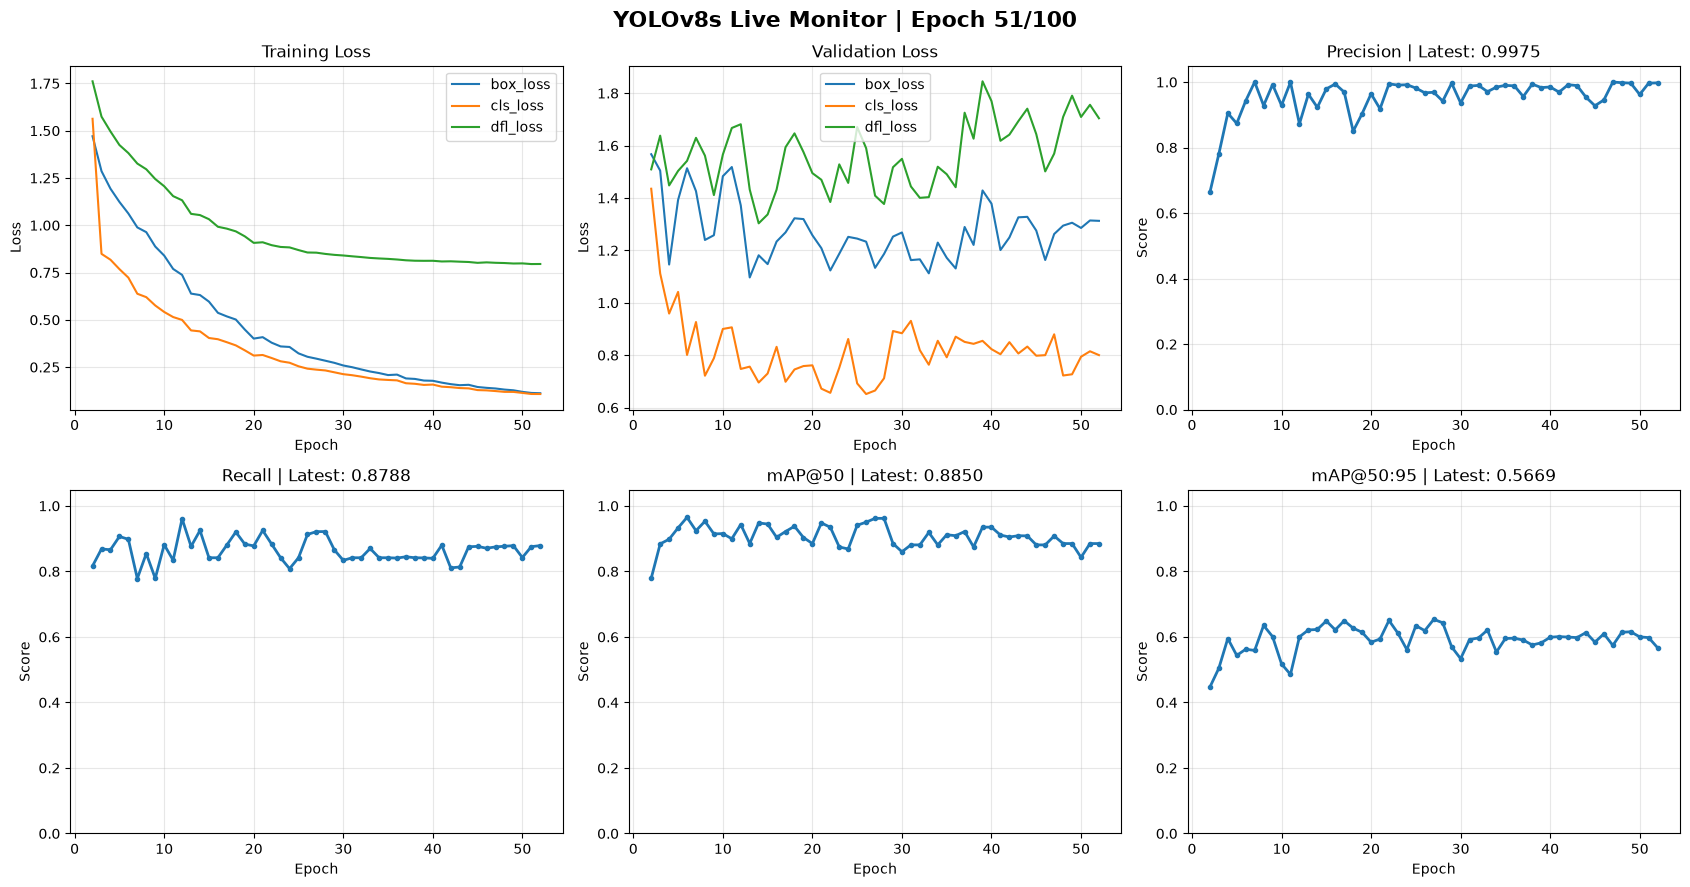

STARTING YOLOv8s FULL TRAINING
New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\Code\object_detection_Project\data\detection_ready\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001,

In [11]:

# %% CELL 8: YOLOv8s LIVE TRAINING DASHBOARD

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import torch
import gc
import time
import traceback

# --------------------------------------------------
# 1. CONFIGURATION
# --------------------------------------------------

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

DATA_YAML = (
    PROJECT_DIR / "data" / "detection_ready" / "data.yaml"
)

RUN_DIR = PROJECT_DIR / "runs"

MODEL_NAME = "YOLOv8s"
CHECKPOINT = "yolov8s.pt"

EPOCHS = 100
IMAGE_SIZE = 640
BATCH_SIZE = 4

SAVE_DIR = RUN_DIR / f"{MODEL_NAME}_LIVE"

if SAVE_DIR.exists():
    raise FileExistsError(
        f"Run directory already exists: {SAVE_DIR}"
    )

assert DATA_YAML.exists()
assert torch.cuda.is_available()

# --------------------------------------------------
# 2. INITIALIZE DASHBOARD
# --------------------------------------------------

plt.ioff()

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 9)
)

fig.suptitle(
    "YOLOv8s - Live Training and Validation Monitor",
    fontsize=17,
    fontweight="bold"
)

ax_train, ax_val, ax_precision, ax_recall, ax_map50, ax_map = (
    axes.flatten()
)

plot_handle = display(fig, display_id=True)

# --------------------------------------------------
# 3. CSV UPDATE FUNCTION
# --------------------------------------------------

def update_dashboard(trainer):

    csv_path = Path(trainer.csv)

    if not csv_path.exists():
        return

    try:
        df = pd.read_csv(csv_path)

        if df.empty:
            return

        df.columns = df.columns.str.strip()

        epochs = df["epoch"] + 1

        # -------------------------------
        # Training loss
        # -------------------------------

        train_loss_cols = [
            "train/box_loss",
            "train/cls_loss",
            "train/dfl_loss"
        ]

        ax_train.clear()

        for col in train_loss_cols:
            if col in df.columns:
                ax_train.plot(
                    epochs,
                    df[col],
                    label=col.split("/")[-1]
                )

        ax_train.set_title("Training Loss")
        ax_train.set_xlabel("Epoch")
        ax_train.set_ylabel("Loss")
        ax_train.legend()
        ax_train.grid(alpha=0.3)

        # -------------------------------
        # Validation loss
        # -------------------------------

        val_loss_cols = [
            "val/box_loss",
            "val/cls_loss",
            "val/dfl_loss"
        ]

        ax_val.clear()

        for col in val_loss_cols:
            if col in df.columns:
                ax_val.plot(
                    epochs,
                    df[col],
                    label=col.split("/")[-1]
                )

        ax_val.set_title("Validation Loss")
        ax_val.set_xlabel("Epoch")
        ax_val.set_ylabel("Loss")
        ax_val.legend()
        ax_val.grid(alpha=0.3)

        # -------------------------------
        # Precision
        # -------------------------------

        metric_columns = {
            ax_precision: (
                "metrics/precision(B)",
                "Precision"
            ),
            ax_recall: (
                "metrics/recall(B)",
                "Recall"
            ),
            ax_map50: (
                "metrics/mAP50(B)",
                "mAP@50"
            ),
            ax_map: (
                "metrics/mAP50-95(B)",
                "mAP@50:95"
            )
        }

        for ax, (column, title) in metric_columns.items():

            ax.clear()

            if column in df.columns:
                ax.plot(
                    epochs,
                    df[column],
                    marker="o",
                    markersize=3,
                    linewidth=2
                )

                latest = df[column].iloc[-1]

                ax.set_title(
                    f"{title} | Latest: {latest:.4f}"
                )

            else:
                ax.set_title(f"{title} - Awaiting metrics")

            ax.set_xlabel("Epoch")
            ax.set_ylabel("Score")
            ax.set_ylim(0, 1.05)
            ax.grid(alpha=0.3)

        current_epoch = len(df)

        fig.suptitle(
            f"YOLOv8s Live Monitor | "
            f"Epoch {current_epoch}/{EPOCHS}",
            fontsize=16,
            fontweight="bold"
        )

        fig.tight_layout()

        # Update existing notebook output
        plot_handle.update(fig)

    except Exception as error:
        print("Dashboard update warning:", error)


# --------------------------------------------------
# 4. LOAD MODEL AND REGISTER CALLBACK
# --------------------------------------------------

model = YOLO(CHECKPOINT)

model.add_callback(
    "on_fit_epoch_end",
    update_dashboard
)

# --------------------------------------------------
# 5. TRAINING
# --------------------------------------------------

print("=" * 65)
print("STARTING YOLOv8s FULL TRAINING")
print("=" * 65)

start_time = time.time()

try:

    results = model.train(

        data=str(DATA_YAML),

        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,

        device=0,
        workers=2,
        amp=True,
        cache=False,

        optimizer="AdamW",
        lr0=0.001,
        weight_decay=0.0005,

        seed=42,
        deterministic=True,

        # No additional online augmentation
        mosaic=0.0,
        mixup=0.0,
        copy_paste=0.0,
        degrees=0.0,
        translate=0.0,
        scale=0.0,
        shear=0.0,
        perspective=0.0,
        fliplr=0.0,
        flipud=0.0,
        hsv_h=0.0,
        hsv_s=0.0,
        hsv_v=0.0,

        # Validation and checkpointing
        val=True,
        save=True,
        save_period=10,
        plots=True,
        patience=25,

        project=str(RUN_DIR),
        name=f"{MODEL_NAME}_LIVE",
        exist_ok=False,

        verbose=True
    )

    training_status = "COMPLETED"

except Exception:
    training_status = "FAILED"
    traceback.print_exc()

finally:

    elapsed = (time.time() - start_time) / 60

    print("\n" + "=" * 65)
    print("TRAINING STATUS:", training_status)
    print(f"Elapsed time: {elapsed:.2f} minutes")
    print("Output directory:", SAVE_DIR)

    torch.cuda.empty_cache()
    gc.collect()

    # Final dashboard refresh
    csv_path = SAVE_DIR / "results.csv"

    if csv_path.exists():
        final_df = pd.read_csv(csv_path)
        print("Recorded epochs:", len(final_df))

    print("=" * 65)


In [12]:

from pathlib import Path
import numpy as np
import pandas as pd
from ultralytics import YOLO

# --------------------------------------------------
# PATHS
# --------------------------------------------------
PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

DATA_YAML = PROJECT_DIR / "data" / "detection_ready" / "data.yaml"

BEST_MODEL = (
    PROJECT_DIR / "runs" / "YOLOv8s_LIVE" /
    "weights" / "best.pt"
)

OUTPUT_DIR = PROJECT_DIR / "reports" / "YOLOv8s_test_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_YAML.exists(), f"Dataset YAML not found: {DATA_YAML}"
assert BEST_MODEL.exists(), f"Best checkpoint not found: {BEST_MODEL}"

# --------------------------------------------------
# LOAD BEST CHECKPOINT
# --------------------------------------------------
model = YOLO(str(BEST_MODEL))

print("=" * 65)
print("YOLOv8s - FINAL TEST SET EVALUATION")
print("=" * 65)

# --------------------------------------------------
# EVALUATE ON TEST SPLIT
# --------------------------------------------------
metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    plots=True,
    save_json=True,
    project=str(OUTPUT_DIR),
    name="test_results",
    exist_ok=True,
    verbose=True
)

# --------------------------------------------------
# EXTRACT OVERALL METRICS
# --------------------------------------------------
box = metrics.box

precision = float(box.mp)
recall = float(box.mr)

# Harmonic mean of overall mean precision and recall
f1_score = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0.0
)

map50 = float(box.map50)
map50_95 = float(box.map)

# Ultralytics composite fitness score
fitness = metrics.results_dict.get("fitness", None)

print("\n" + "=" * 65)
print("OVERALL TEST PERFORMANCE")
print("=" * 65)

print(f"Precision       : {precision:.4f}")
print(f"Recall          : {recall:.4f}")
print(f"F1-score        : {f1_score:.4f}")
print(f"mAP@50          : {map50:.4f}")
print(f"mAP@50:95       : {map50_95:.4f}")

if fitness is not None:
    print(f"Fitness score   : {float(fitness):.4f}")

# --------------------------------------------------
# PER-CLASS METRICS
# --------------------------------------------------
class_names = model.names
class_ids = sorted(class_names.keys())

class_results = []

for class_id in class_ids:
    p = float(box.p[class_id])
    r = float(box.r[class_id])

    f1 = (
        2 * p * r / (p + r)
        if p + r > 0 else 0.0
    )

    class_results.append({
        "Class": class_names[class_id],
        "Precision": p,
        "Recall": r,
        "F1-score": f1,
        "mAP@50": float(box.ap50[class_id]),
        "mAP@50:95": float(box.ap[class_id])
    })

class_df = pd.DataFrame(class_results)

print("\n" + "=" * 65)
print("PER-CLASS TEST PERFORMANCE")
print("=" * 65)

print(class_df.round(4).to_string(index=False))

# --------------------------------------------------
# SAVE RESULTS
# --------------------------------------------------
summary_df = pd.DataFrame([{
    "Model": "YOLOv8s",
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1_score,
    "mAP@50": map50,
    "mAP@50:95": map50_95,
    "Fitness": float(fitness) if fitness is not None else np.nan
}])

summary_df.to_csv(
    OUTPUT_DIR / "overall_test_metrics.csv",
    index=False
)

class_df.to_csv(
    OUTPUT_DIR / "per_class_test_metrics.csv",
    index=False
)

print("\nResults saved to:")
print(OUTPUT_DIR)

print("\nTEST EVALUATION COMPLETED.")


YOLOv8s - FINAL TEST SET EVALUATION
Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 324.9±111.5 MB/s, size: 38.2 KB)
val: Scanning G:\Code\object_detection_Project\data\detection_ready\test\labels... 21 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 21/21 1.6Kit/s 0.0s
val: New cache created: G:\Code\object_detection_Project\data\detection_ready\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.9it/s 2.0s0.3ss
                   all         21         29      0.891      0.853      0.858      0.583
                  Good         13         14      0.782      0.786       0.78      0.508
            Miss_Print         15         15          1      0.921      0.935      0.659
Speed: 1.2ms preprocess, 8.0ms inference, 

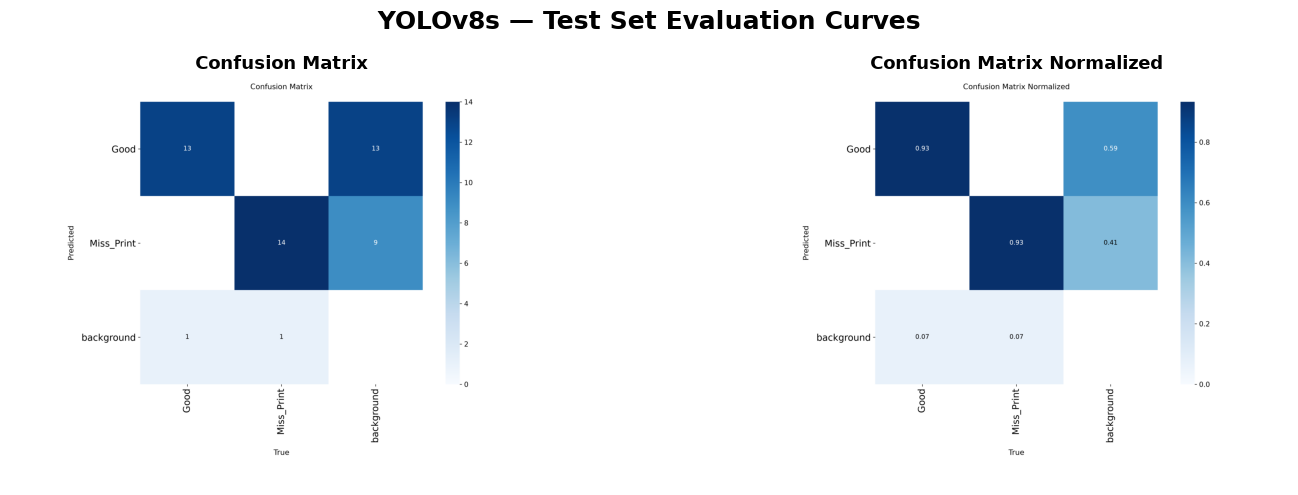

Combined figure saved: G:\Code\object_detection_Project\reports\YOLOv8s_test_evaluation\test_results\YOLOv8s_test_curves_combined.png


In [13]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import math

# Test evaluation output directory
RESULT_DIR = Path(
    r"G:\Code\object_detection_Project\reports"
    r"\YOLOv8s_test_evaluation\test_results"
)

# Expected detection evaluation plots
curve_files = [
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png"
]

available = [
    RESULT_DIR / filename
    for filename in curve_files
    if (RESULT_DIR / filename).exists()
]

if not available:
    print("No evaluation plots found in:", RESULT_DIR)
    print("Available PNG files:")
    for file in RESULT_DIR.glob("*.png"):
        print(file.name)
else:
    cols = 2
    rows = math.ceil(len(available) / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(15, 5 * rows)
    )

    axes = axes.flatten()

    for ax, file in zip(axes, available):
        img = Image.open(file)
        ax.imshow(img)
        ax.set_title(file.stem.replace("_", " ").title(),
                     fontsize=13, fontweight="bold")
        ax.axis("off")

    for ax in axes[len(available):]:
        ax.axis("off")

    fig.suptitle(
        "YOLOv8s — Test Set Evaluation Curves",
        fontsize=18,
        fontweight="bold"
    )

    plt.tight_layout()
    
    save_path = RESULT_DIR / "YOLOv8s_test_curves_combined.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Combined figure saved:", save_path)


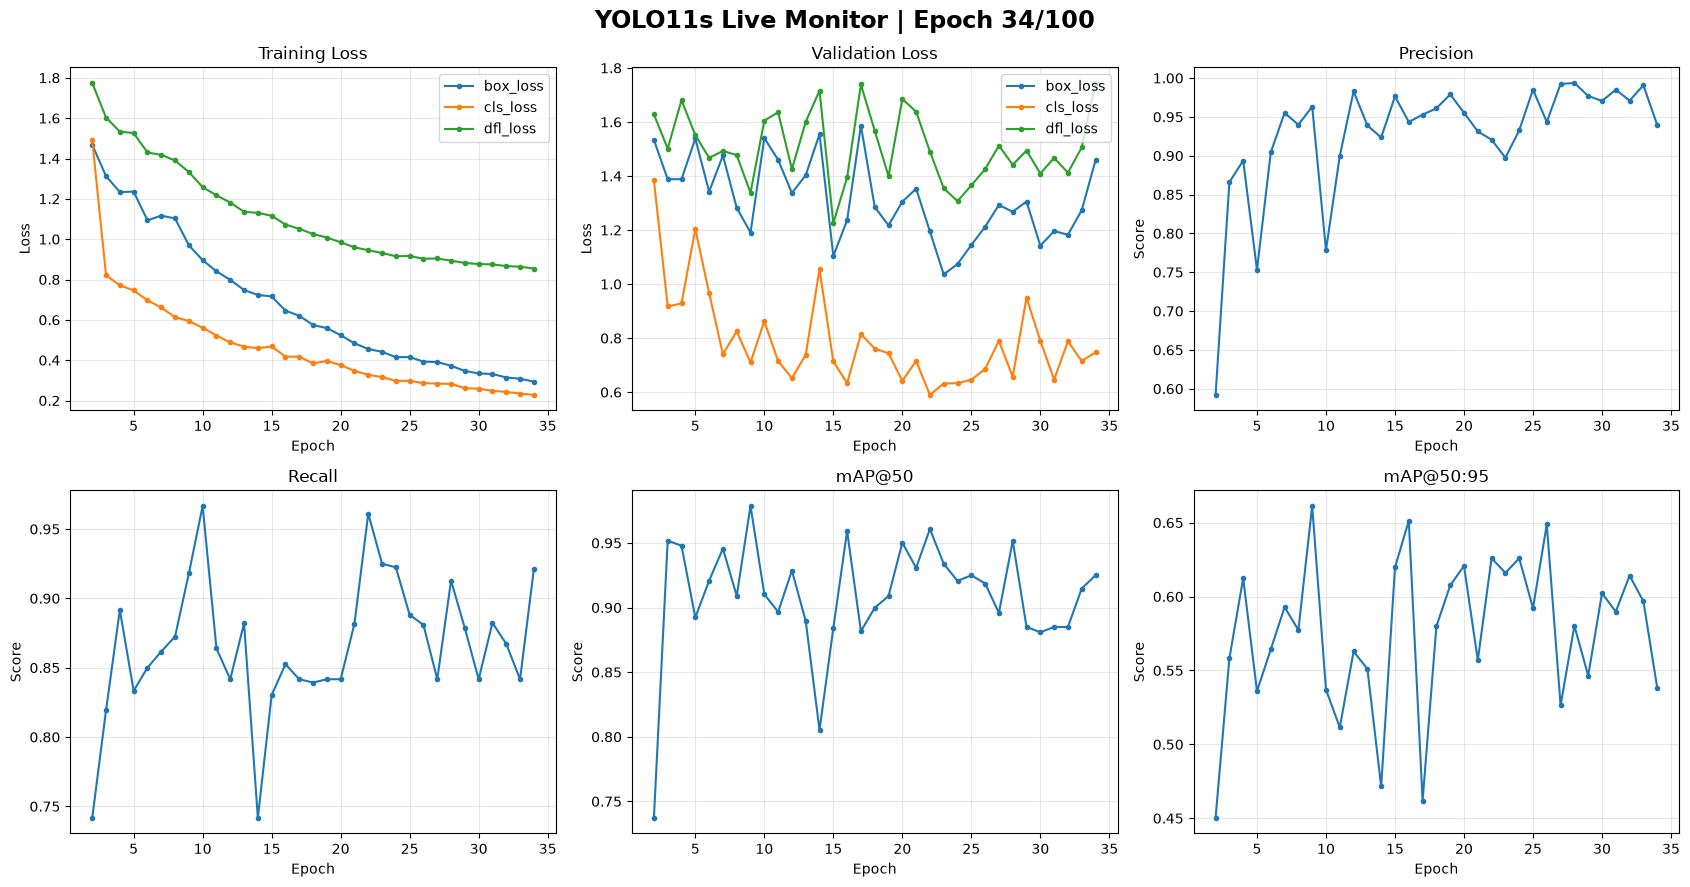

STARTING YOLO11s TRAINING
New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\Code\object_detection_Project\data\detection_ready\data.yaml, degrees=0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0, flipud=0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_rat

In [14]:

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import torch
import gc
import time

# ==================================================
# CONFIGURATION
# ==================================================
PROJECT_DIR = Path(r"G:\Code\object_detection_Project")
DATA_YAML = PROJECT_DIR / "data" / "detection_ready" / "data.yaml"
RUN_DIR = PROJECT_DIR / "runs"

MODEL_NAME = "YOLO11s"
CHECKPOINT = "yolo11s.pt"

EPOCHS = 100
IMAGE_SIZE = 640
BATCH_SIZE = 4

SAVE_DIR = RUN_DIR / f"{MODEL_NAME}_LIVE"

if SAVE_DIR.exists():
    raise FileExistsError(
        f"Output directory already exists: {SAVE_DIR}\n"
        "Choose a new run name or inspect the existing results first."
    )

assert DATA_YAML.exists(), f"Dataset not found: {DATA_YAML}"

# ==================================================
# LIVE TRAINING DASHBOARD
# ==================================================
plt.ioff()

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
plot_handle = display(fig, display_id=True)

def update_dashboard(trainer):
    csv_path = Path(trainer.csv)

    if not csv_path.exists():
        return

    try:
        df = pd.read_csv(csv_path)
        if df.empty:
            return

        df.columns = df.columns.str.strip()
        epochs = df["epoch"] + 1

        metric_groups = [
            (
                axes[0, 0],
                ["train/box_loss", "train/cls_loss", "train/dfl_loss"],
                "Training Loss",
                "Loss"
            ),
            (
                axes[0, 1],
                ["val/box_loss", "val/cls_loss", "val/dfl_loss"],
                "Validation Loss",
                "Loss"
            ),
            (
                axes[0, 2],
                ["metrics/precision(B)"],
                "Precision",
                "Score"
            ),
            (
                axes[1, 0],
                ["metrics/recall(B)"],
                "Recall",
                "Score"
            ),
            (
                axes[1, 1],
                ["metrics/mAP50(B)"],
                "mAP@50",
                "Score"
            ),
            (
                axes[1, 2],
                ["metrics/mAP50-95(B)"],
                "mAP@50:95",
                "Score"
            )
        ]

        for ax, columns, title, ylabel in metric_groups:
            ax.clear()

            for column in columns:
                if column in df.columns:
                    ax.plot(
                        epochs,
                        df[column],
                        marker="." if len(df) < 60 else None,
                        label=column.split("/")[-1]
                    )

            ax.set_title(title)
            ax.set_xlabel("Epoch")
            ax.set_ylabel(ylabel)
            ax.grid(True, alpha=0.3)

            if len(columns) > 1:
                ax.legend()

        latest_epoch = int(df["epoch"].iloc[-1]) + 1

        fig.suptitle(
            f"{MODEL_NAME} Live Monitor | "
            f"Epoch {latest_epoch}/{EPOCHS}",
            fontsize=17,
            fontweight="bold"
        )

        fig.tight_layout()
        plot_handle.update(fig)

    except Exception as error:
        print("Dashboard update warning:", error)


# ==================================================
# LOAD MODEL
# ==================================================
model = YOLO(CHECKPOINT)
model.add_callback("on_fit_epoch_end", update_dashboard)

print("=" * 65)
print("STARTING YOLO11s TRAINING")
print("=" * 65)

start_time = time.time()

try:
    results = model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,

        device=0,
        workers=2,
        amp=True,
        cache=False,

        optimizer="AdamW",
        lr0=0.001,
        weight_decay=0.0005,

        seed=42,
        deterministic=True,

        # Same augmentation protocol as YOLOv8s
        mosaic=0,
        mixup=0,
        copy_paste=0,
        degrees=0,
        translate=0,
        scale=0,
        shear=0,
        perspective=0,
        fliplr=0,
        flipud=0,
        hsv_h=0,
        hsv_s=0,
        hsv_v=0,

        val=True,
        save=True,
        save_period=10,
        plots=True,
        patience=25,

        project=str(RUN_DIR),
        name="YOLO11s_LIVE",
        exist_ok=False,
        verbose=True
    )

    print("\nYOLO11s TRAINING COMPLETED")

except Exception as error:
    print("\nYOLO11s TRAINING FAILED:")
    print(error)
    raise

finally:
    elapsed = (time.time() - start_time) / 60

    print("\nElapsed time:", round(elapsed, 2), "minutes")
    print("Output directory:", SAVE_DIR)

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ==================================================
# TRAINING SUMMARY
# ==================================================
results_csv = SAVE_DIR / "results.csv"

if results_csv.exists():
    history = pd.read_csv(results_csv)
    print("\nRecorded epochs:", len(history))
    print("Best checkpoint:", SAVE_DIR / "weights" / "best.pt")
    print("Last checkpoint:", SAVE_DIR / "weights" / "last.pt")


In [15]:

from pathlib import Path
import pandas as pd
from ultralytics import YOLO

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

BEST_MODEL = (
    PROJECT_DIR / "runs" / "YOLO11s_LIVE" /
    "weights" / "best.pt"
)

DATA_YAML = (
    PROJECT_DIR / "data" / "detection_ready" / "data.yaml"
)

OUTPUT_DIR = (
    PROJECT_DIR / "reports" / "YOLO11s_test_evaluation"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert BEST_MODEL.exists(), f"Checkpoint missing: {BEST_MODEL}"

model = YOLO(str(BEST_MODEL))

print("=" * 60)
print("YOLO11s - FINAL TEST EVALUATION")
print("=" * 60)

metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    plots=False,
    project=str(OUTPUT_DIR),
    name="test_results",
    exist_ok=True,
    verbose=True
)

box = metrics.box

p = float(box.mp)
r = float(box.mr)

f1 = 2 * p * r / (p + r) if (p + r) else 0.0

overall = pd.DataFrame([{
    "Model": "YOLO11s",
    "Precision": p,
    "Recall": r,
    "F1-score": f1,
    "mAP@50": float(box.map50),
    "mAP@50:95": float(box.map)
}])

per_class = []

for class_id, class_name in model.names.items():
    cp = float(box.p[class_id])
    cr = float(box.r[class_id])
    cf1 = 2 * cp * cr / (cp + cr) if (cp + cr) else 0.0

    per_class.append({
        "Class": class_name,
        "Precision": cp,
        "Recall": cr,
        "F1-score": cf1,
        "mAP@50": float(box.ap50[class_id]),
        "mAP@50:95": float(box.ap[class_id])
    })

per_class_df = pd.DataFrame(per_class)

print("\nOVERALL TEST RESULTS")
print(overall.round(4).to_string(index=False))

print("\nPER-CLASS TEST RESULTS")
print(per_class_df.round(4).to_string(index=False))

overall.to_csv(
    OUTPUT_DIR / "overall_test_metrics.csv",
    index=False
)

per_class_df.to_csv(
    OUTPUT_DIR / "per_class_test_metrics.csv",
    index=False
)

print("\nSaved results to:", OUTPUT_DIR)


YOLO11s - FINAL TEST EVALUATION
Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 524.0±161.8 MB/s, size: 38.2 KB)
val: Scanning G:\Code\object_detection_Project\data\detection_ready\test\labels.cache... 21 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 21/21  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.1it/s 1.9s<0.1s
                   all         21         29      0.854      0.877      0.907      0.625
                  Good         13         14      0.837      0.857      0.892      0.583
            Miss_Print         15         15       0.87      0.897      0.921      0.666
Speed: 0.7ms preprocess, 5.6ms inference, 0.0ms loss, 0.8ms postprocess per image

OVERALL TEST RESULTS
  Model  Precision  Recall  F1-score  

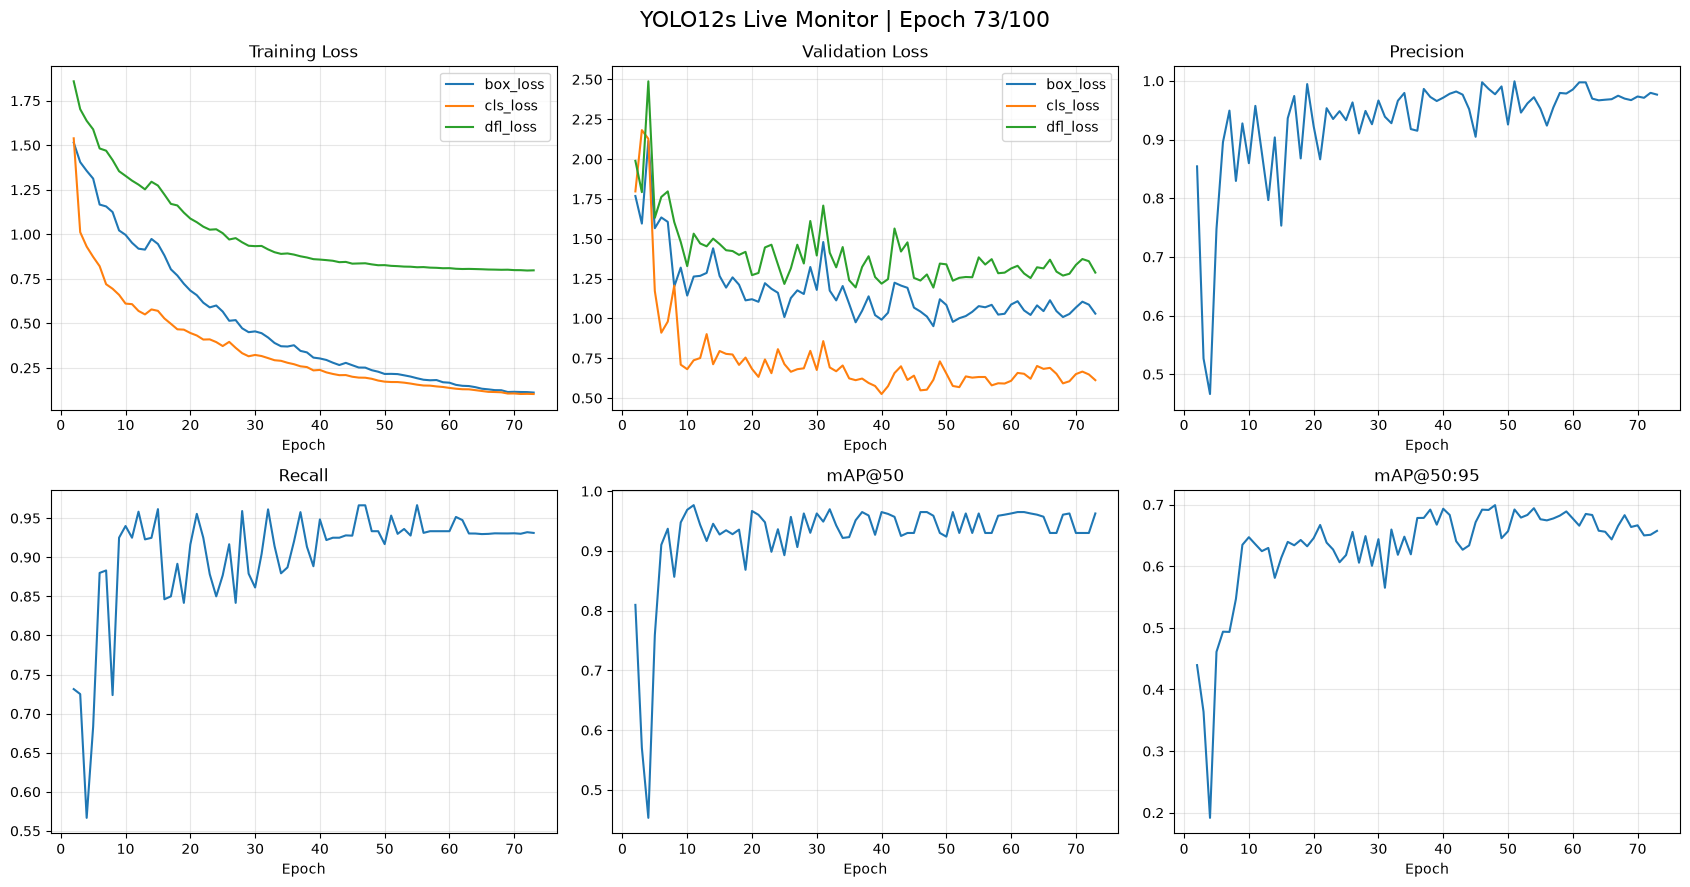

STARTING YOLO12s TRAINING
New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\Code\object_detection_Project\data\detection_ready\data.yaml, degrees=0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0, flipud=0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_rat

In [16]:

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import torch
import gc
import time

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")
DATA_YAML = PROJECT_DIR / "data" / "detection_ready" / "data.yaml"
RUN_DIR = PROJECT_DIR / "runs"

MODEL_NAME = "YOLO12s"
CHECKPOINT = "yolo12s.pt"

EPOCHS = 100
SAVE_DIR = RUN_DIR / "YOLO12s_LIVE"

if SAVE_DIR.exists():
    raise FileExistsError(f"Run directory already exists: {SAVE_DIR}")

assert DATA_YAML.exists()

# ---------------- LIVE DASHBOARD ----------------
plt.ioff()

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
plot_handle = display(fig, display_id=True)

def update_dashboard(trainer):
    csv_path = Path(trainer.csv)

    if not csv_path.exists():
        return

    try:
        df = pd.read_csv(csv_path)
        df.columns = df.columns.str.strip()

        if df.empty:
            return

        epochs = df["epoch"] + 1

        groups = [
            (axes[0, 0], ["train/box_loss", "train/cls_loss",
                          "train/dfl_loss"], "Training Loss"),
            (axes[0, 1], ["val/box_loss", "val/cls_loss",
                          "val/dfl_loss"], "Validation Loss"),
            (axes[0, 2], ["metrics/precision(B)"], "Precision"),
            (axes[1, 0], ["metrics/recall(B)"], "Recall"),
            (axes[1, 1], ["metrics/mAP50(B)"], "mAP@50"),
            (axes[1, 2], ["metrics/mAP50-95(B)"], "mAP@50:95")
        ]

        for ax, columns, title in groups:
            ax.clear()

            for col in columns:
                if col in df.columns:
                    ax.plot(epochs, df[col], label=col.split("/")[-1])

            ax.set_title(title)
            ax.set_xlabel("Epoch")
            ax.grid(True, alpha=0.3)

            if len(columns) > 1:
                ax.legend()

        fig.suptitle(
            f"YOLO12s Live Monitor | Epoch {int(df['epoch'].iloc[-1])+1}/{EPOCHS}",
            fontsize=16
        )

        fig.tight_layout()
        plot_handle.update(fig)

    except Exception as e:
        print("Dashboard warning:", e)


# ---------------- TRAINING ----------------
model = YOLO(CHECKPOINT)
model.add_callback("on_fit_epoch_end", update_dashboard)

print("=" * 60)
print("STARTING YOLO12s TRAINING")
print("=" * 60)

start_time = time.time()

try:
    model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        imgsz=640,
        batch=4,
        device=0,
        workers=2,
        amp=True,
        cache=False,

        optimizer="AdamW",
        lr0=0.001,
        weight_decay=0.0005,

        seed=42,
        deterministic=True,

        mosaic=0,
        mixup=0,
        copy_paste=0,
        degrees=0,
        translate=0,
        scale=0,
        shear=0,
        perspective=0,
        fliplr=0,
        flipud=0,
        hsv_h=0,
        hsv_s=0,
        hsv_v=0,

        val=True,
        save=True,
        save_period=10,
        plots=True,
        patience=25,

        project=str(RUN_DIR),
        name="YOLO12s_LIVE",
        exist_ok=False,
        verbose=True
    )

    print("\nYOLO12s TRAINING COMPLETED")

except Exception as e:
    print("\nTRAINING FAILED:", e)
    raise

finally:
    print("Elapsed minutes:", round((time.time()-start_time)/60, 2))
    print("Output:", SAVE_DIR)

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ---------------- SUMMARY ----------------
results_csv = SAVE_DIR / "results.csv"

if results_csv.exists():
    history = pd.read_csv(results_csv)
    print("Recorded epochs:", len(history))
    print("Best checkpoint:", SAVE_DIR / "weights" / "best.pt")


In [17]:

from pathlib import Path
import pandas as pd
from ultralytics import YOLO

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

BEST_MODEL = (
    PROJECT_DIR / "runs" / "YOLO12s_LIVE" /
    "weights" / "best.pt"
)

DATA_YAML = (
    PROJECT_DIR / "data" / "detection_ready" / "data.yaml"
)

OUTPUT_DIR = (
    PROJECT_DIR / "reports" / "YOLO12s_test_evaluation"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert BEST_MODEL.exists(), f"Checkpoint missing: {BEST_MODEL}"

model = YOLO(str(BEST_MODEL))

print("=" * 60)
print("YOLO12s - FINAL TEST EVALUATION")
print("=" * 60)

metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    plots=False,
    project=str(OUTPUT_DIR),
    name="test_results",
    exist_ok=True,
    verbose=True
)

box = metrics.box

p = float(box.mp)
r = float(box.mr)
f1 = 2 * p * r / (p + r) if (p + r) else 0.0

overall = pd.DataFrame([{
    "Model": "YOLO12s",
    "Precision": p,
    "Recall": r,
    "F1-score": f1,
    "mAP@50": float(box.map50),
    "mAP@50:95": float(box.map)
}])

per_class = []

for class_id, class_name in model.names.items():
    cp = float(box.p[class_id])
    cr = float(box.r[class_id])
    cf1 = 2 * cp * cr / (cp + cr) if (cp + cr) else 0.0

    per_class.append({
        "Class": class_name,
        "Precision": cp,
        "Recall": cr,
        "F1-score": cf1,
        "mAP@50": float(box.ap50[class_id]),
        "mAP@50:95": float(box.ap[class_id])
    })

per_class_df = pd.DataFrame(per_class)

print("\nOVERALL TEST RESULTS")
print(overall.round(4).to_string(index=False))

print("\nPER-CLASS TEST RESULTS")
print(per_class_df.round(4).to_string(index=False))

overall.to_csv(OUTPUT_DIR / "overall_test_metrics.csv", index=False)
per_class_df.to_csv(OUTPUT_DIR / "per_class_test_metrics.csv", index=False)

print("\nSaved results to:", OUTPUT_DIR)


YOLO12s - FINAL TEST EVALUATION
Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
YOLOv12s summary (fused): 159 layers, 9,231,654 parameters, 0 gradients, 23.2 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 650.3±206.3 MB/s, size: 38.2 KB)
val: Scanning G:\Code\object_detection_Project\data\detection_ready\test\labels.cache... 21 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 21/21  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.0it/s 2.0s0.3ss
                   all         21         29          1      0.958       0.96      0.727
                  Good         13         14          1      0.926      0.925       0.71
            Miss_Print         15         15          1       0.99      0.995      0.744
Speed: 1.1ms preprocess, 9.3ms inference, 0.0ms loss, 0.8ms postprocess per image

OVERALL TEST RESULTS
  Model  Precision  Recall  F1-score 

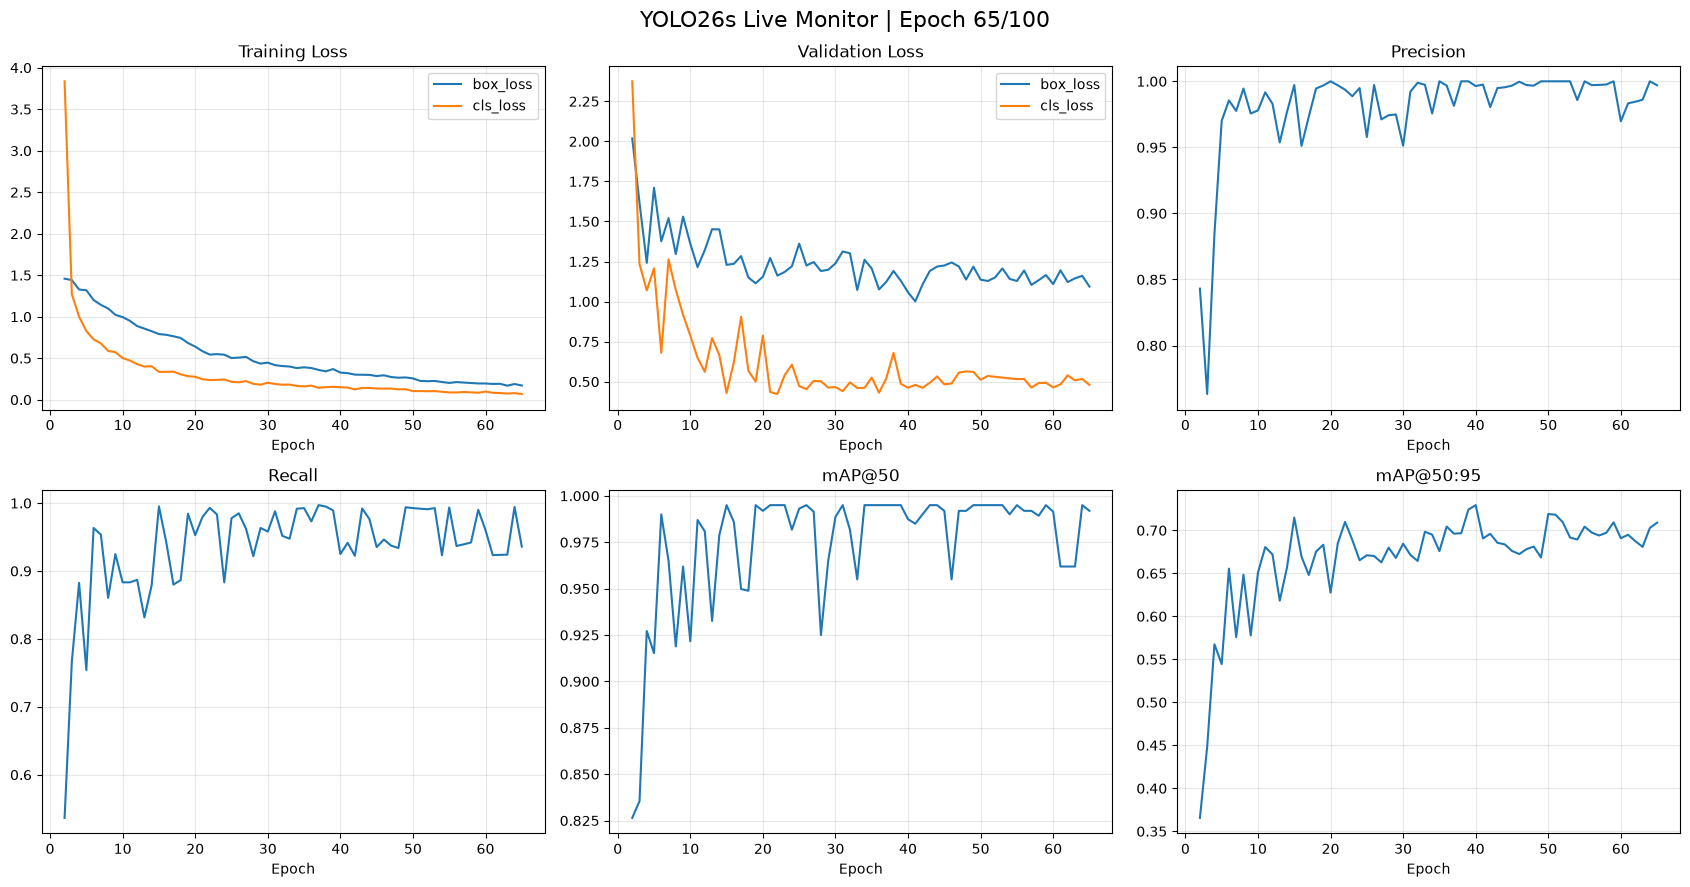

STARTING YOLO26s TRAINING
New https://pypi.org/project/ultralytics/8.4.208 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\Code\object_detection_Project\data\detection_ready\data.yaml, degrees=0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0, flipud=0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_rat

In [18]:

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import torch
import gc
import time

# Configuration
PROJECT_DIR = Path(r"G:\Code\object_detection_Project")
DATA_YAML = PROJECT_DIR / "data" / "detection_ready" / "data.yaml"
RUN_DIR = PROJECT_DIR / "runs"

MODEL_NAME = "YOLO26s"
CHECKPOINT = "yolo26s.pt"
EPOCHS = 100

SAVE_DIR = RUN_DIR / "YOLO26s_LIVE"

if SAVE_DIR.exists():
    raise FileExistsError(f"Run directory already exists: {SAVE_DIR}")

assert DATA_YAML.exists()

# Live dashboard
plt.ioff()
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
plot_handle = display(fig, display_id=True)

def update_dashboard(trainer):
    csv_path = Path(trainer.csv)

    if not csv_path.exists():
        return

    try:
        df = pd.read_csv(csv_path)
        df.columns = df.columns.str.strip()

        if df.empty:
            return

        epochs = df["epoch"] + 1

        groups = [
            (axes[0, 0], ["train/box_loss", "train/cls_loss",
                          "train/dfl_loss"], "Training Loss"),
            (axes[0, 1], ["val/box_loss", "val/cls_loss",
                          "val/dfl_loss"], "Validation Loss"),
            (axes[0, 2], ["metrics/precision(B)"], "Precision"),
            (axes[1, 0], ["metrics/recall(B)"], "Recall"),
            (axes[1, 1], ["metrics/mAP50(B)"], "mAP@50"),
            (axes[1, 2], ["metrics/mAP50-95(B)"], "mAP@50:95")
        ]

        for ax, columns, title in groups:
            ax.clear()

            for col in columns:
                if col in df.columns:
                    ax.plot(epochs, df[col], label=col.split("/")[-1])

            ax.set_title(title)
            ax.set_xlabel("Epoch")
            ax.grid(True, alpha=0.3)

            if len(columns) > 1:
                ax.legend()

        fig.suptitle(
            f"YOLO26s Live Monitor | Epoch "
            f"{int(df['epoch'].iloc[-1])+1}/{EPOCHS}",
            fontsize=16
        )

        fig.tight_layout()
        plot_handle.update(fig)

    except Exception as e:
        print("Dashboard warning:", e)


# Load model
model = YOLO(CHECKPOINT)
model.add_callback("on_fit_epoch_end", update_dashboard)

print("=" * 60)
print("STARTING YOLO26s TRAINING")
print("=" * 60)

start_time = time.time()

try:
    model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        imgsz=640,
        batch=4,

        device=0,
        workers=2,
        amp=True,
        cache=False,

        optimizer="AdamW",
        lr0=0.001,
        weight_decay=0.0005,

        seed=42,
        deterministic=True,

        # Same augmentation protocol
        mosaic=0,
        mixup=0,
        copy_paste=0,
        degrees=0,
        translate=0,
        scale=0,
        shear=0,
        perspective=0,
        fliplr=0,
        flipud=0,
        hsv_h=0,
        hsv_s=0,
        hsv_v=0,

        val=True,
        save=True,
        save_period=10,
        plots=True,
        patience=25,

        project=str(RUN_DIR),
        name="YOLO26s_LIVE",
        exist_ok=False,
        verbose=True
    )

    print("\nYOLO26s TRAINING COMPLETED")

except Exception as e:
    print("\nTRAINING FAILED:", e)
    raise

finally:
    print("Elapsed minutes:", round((time.time()-start_time)/60, 2))
    print("Output:", SAVE_DIR)

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Training summary
results_csv = SAVE_DIR / "results.csv"

if results_csv.exists():
    history = pd.read_csv(results_csv)
    print("Recorded epochs:", len(history))
    print("Best checkpoint:", SAVE_DIR / "weights" / "best.pt")


In [19]:

from pathlib import Path
import pandas as pd
from ultralytics import YOLO

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

BEST_MODEL = (
    PROJECT_DIR / "runs" / "YOLO26s_LIVE" / "weights" / "best.pt"
)

DATA_YAML = (
    PROJECT_DIR / "data" / "detection_ready" / "data.yaml"
)

OUTPUT_DIR = (
    PROJECT_DIR / "reports" / "YOLO26s_test_evaluation"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert BEST_MODEL.exists(), f"Missing checkpoint: {BEST_MODEL}"
assert DATA_YAML.exists(), f"Missing dataset YAML: {DATA_YAML}"

model = YOLO(str(BEST_MODEL))

metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    plots=True,
    project=str(OUTPUT_DIR),
    name="test_results",
    exist_ok=True,
    verbose=True
)

box = metrics.box

# Overall metrics
precision = float(box.mp)
recall = float(box.mr)

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0.0
)

overall = pd.DataFrame([{
    "Model": "YOLO26s",
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "mAP@50": float(box.map50),
    "mAP@50:95": float(box.map)
}])

# Per-class metrics
per_class = []

for class_id, class_name in model.names.items():

    cp = float(box.p[class_id])
    cr = float(box.r[class_id])

    cf1 = (
        2 * cp * cr / (cp + cr)
        if cp + cr > 0 else 0.0
    )

    per_class.append({
        "Class": class_name,
        "Precision": cp,
        "Recall": cr,
        "F1-score": cf1,
        "mAP@50": float(box.ap50[class_id]),
        "mAP@50:95": float(box.ap[class_id])
    })

per_class_df = pd.DataFrame(per_class)

# Save results
overall.to_csv(
    OUTPUT_DIR / "YOLO26s_overall_test_metrics.csv",
    index=False
)

per_class_df.to_csv(
    OUTPUT_DIR / "YOLO26s_per_class_test_metrics.csv",
    index=False
)

print("\n" + "=" * 60)
print("YOLO26s FINAL TEST RESULTS")
print("=" * 60)

print("\nOVERALL:")
print(overall.to_string(index=False))

print("\nPER CLASS:")
print(per_class_df.to_string(index=False))

print("\nSaved to:", OUTPUT_DIR)


Ultralytics 8.4.190  Python-3.11.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
YOLO26s summary (fused): 120 layers, 9,465,954 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 305.4±92.3 MB/s, size: 38.2 KB)
val: Scanning G:\Code\object_detection_Project\data\detection_ready\test\labels.cache... 21 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 21/21  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.5it/s 2.4s0.1ss
                   all         21         29      0.949      0.895      0.919      0.697
                  Good         13         14      0.922      0.857       0.85      0.599
            Miss_Print         15         15      0.977      0.933      0.988      0.795
Speed: 1.2ms preprocess, 14.9ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to G:\Code\object_detection_Project\reports\YOLO26s_test_evaluation\test_resul

In [20]:
pip install pandas matplotlib numpy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. PROJECT CONFIGURATION
# ============================================================

PROJECT_DIR = Path(r"G:\Code\object_detection_Project")

RUNS_DIR = PROJECT_DIR / "runs"
OUTPUT_DIR = PROJECT_DIR / "reports" / "comparison_visualizations"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "YOLOv8s": RUNS_DIR / "YOLOv8s_LIVE" / "results.csv",
    "YOLO11s": RUNS_DIR / "YOLO11s_LIVE" / "results.csv",
    "YOLO12s": RUNS_DIR / "YOLO12s_LIVE" / "results.csv",
    "YOLO26s": RUNS_DIR / "YOLO26s_LIVE" / "results.csv",
}

# Publication-quality figure configuration
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


# ============================================================
# 2. ACTUAL TEST-SET RESULTS
# ============================================================

overall = pd.DataFrame([
    ["YOLOv8s", 0.8910, 0.8534, 0.8718, 0.8577, 0.5834],
    ["YOLO11s", 0.8535, 0.8772, 0.8652, 0.9066, 0.6246],
    ["YOLO12s", 1.0000, 0.9577, 0.9784, 0.9600, 0.7271],
    ["YOLO26s", 0.949227, 0.895238, 0.921443,
     0.918778, 0.696852],
], columns=[
    "Model", "Precision", "Recall", "F1-score",
    "mAP@50", "mAP@50:95"
])


per_class = pd.DataFrame([
    ["YOLOv8s", "Good", 0.7819, 0.7857, 0.7838, 0.7803, 0.5083],
    ["YOLOv8s", "Miss_Print", 1.0000, 0.9211, 0.9589, 0.9350, 0.6585],

    ["YOLO11s", "Good", 0.8365, 0.8571, 0.8467, 0.8920, 0.5830],
    ["YOLO11s", "Miss_Print", 0.8705, 0.8972, 0.8837, 0.9213, 0.6662],

    ["YOLO12s", "Good", 1.0000, 0.9258, 0.9615, 0.9250, 0.7105],
    ["YOLO12s", "Miss_Print", 1.0000, 0.9896, 0.9948, 0.9950, 0.7438],

    ["YOLO26s", "Good", 0.921791, 0.857143, 0.888292,
     0.849615, 0.599107],
    ["YOLO26s", "Miss_Print", 0.976664, 0.933333, 0.954507,
     0.987941, 0.794597],
], columns=[
    "Model", "Class", "Precision", "Recall",
    "F1-score", "mAP@50", "mAP@50:95"
])

overall.to_csv(OUTPUT_DIR / "overall_test_results.csv", index=False)
per_class.to_csv(OUTPUT_DIR / "per_class_test_results.csv", index=False)


# ============================================================
# 3. LOAD TRAINING HISTORIES
# ============================================================

histories = {}

for model_name, csv_path in MODELS.items():

    if not csv_path.exists():
        print(f"[WARNING] Missing training history: {csv_path}")
        continue

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    histories[model_name] = df

    print(
        f"[LOADED] {model_name}: "
        f"{len(df)} epochs"
    )

if not histories:
    raise FileNotFoundError(
        "No results.csv files found. Check RUNS_DIR and model folders."
    )


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def save_figure(fig, filename):

    fig.savefig(
        OUTPUT_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        OUTPUT_DIR / f"{filename}.pdf",
        bbox_inches="tight"
    )

    plt.close(fig)


def plot_history_metric(ax, metric, title, ylabel):

    for model_name, df in histories.items():

        if metric not in df.columns:
            print(f"[SKIP] {model_name}: missing {metric}")
            continue

        epochs = np.arange(1, len(df) + 1)

        ax.plot(
            epochs,
            df[metric],
            linewidth=1.8,
            label=model_name
        )

        # Mark the best validation mAP50-95 epoch
        best_col = "metrics/mAP50-95(B)"

        if best_col in df.columns:
            best_epoch = df[best_col].idxmax() + 1

            ax.axvline(
                best_epoch,
                linestyle=":",
                linewidth=0.9,
                alpha=0.45
            )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.25)
    ax.legend()


# ============================================================
# 5. TRAINING AND VALIDATION LOSS CURVES
# ============================================================

# Box loss
fig, ax = plt.subplots(figsize=(10, 6))

plot_history_metric(
    ax,
    "train/box_loss",
    "Training Box Loss Comparison",
    "Box Loss"
)

save_figure(fig, "01_training_box_loss")


# Validation box loss
fig, ax = plt.subplots(figsize=(10, 6))

plot_history_metric(
    ax,
    "val/box_loss",
    "Validation Box Loss Comparison",
    "Box Loss"
)

save_figure(fig, "02_validation_box_loss")


# Classification loss
fig, ax = plt.subplots(figsize=(10, 6))

plot_history_metric(
    ax,
    "train/cls_loss",
    "Training Classification Loss Comparison",
    "Classification Loss"
)

save_figure(fig, "03_training_classification_loss")


fig, ax = plt.subplots(figsize=(10, 6))

plot_history_metric(
    ax,
    "val/cls_loss",
    "Validation Classification Loss Comparison",
    "Classification Loss"
)

save_figure(fig, "04_validation_classification_loss")


# Auxiliary localization losses:
# YOLOv8/11/12 use DFL; YOLO26 reports L1.
# These are different objectives and should NOT be
# interpreted as directly comparable loss magnitudes.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_name, df in histories.items():

    epochs = np.arange(1, len(df) + 1)

    if "train/dfl_loss" in df.columns:
        axes[0].plot(
            epochs, df["train/dfl_loss"],
            label=model_name, linewidth=1.7
        )

    if "train/l1_loss" in df.columns:
        axes[1].plot(
            epochs, df["train/l1_loss"],
            label=model_name, linewidth=1.7
        )

axes[0].set_title("Training DFL Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("DFL Loss")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].set_title("Training L1 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("L1 Loss")
axes[1].grid(alpha=0.25)
axes[1].legend()

fig.suptitle("Model-specific Auxiliary Localization Losses")
fig.tight_layout()

save_figure(fig, "05_auxiliary_localization_losses")


# ============================================================
# 6. EPOCH-WISE DETECTION METRICS
# ============================================================

epoch_metrics = [
    ("metrics/precision(B)", "Precision", "Precision"),
    ("metrics/recall(B)", "Recall", "Recall"),
    ("metrics/mAP50(B)", "mAP@50", "mAP@50"),
    ("metrics/mAP50-95(B)", "mAP@50:95", "mAP@50:95"),
]

for column, title, ylabel in epoch_metrics:

    fig, ax = plt.subplots(figsize=(10, 6))

    plot_history_metric(
        ax,
        column,
        f"Validation {title} Across Epochs",
        ylabel
    )

    ax.set_ylim(0, 1.05)

    save_figure(
        fig,
        f"06_epochwise_{title.replace('@', '_').replace(':', '_')}"
    )


# ============================================================
# 7. OVERALL TEST-SET COMPARISON
# ============================================================

metrics = [
    "Precision", "Recall", "F1-score",
    "mAP@50", "mAP@50:95"
]

fig, ax = plt.subplots(figsize=(12, 6))

overall.set_index("Model")[metrics].plot(
    kind="bar",
    ax=ax,
    width=0.78
)

ax.set_title("Overall Test-Set Performance Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.08)
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right", ncol=2)

save_figure(fig, "07_overall_test_comparison")


# Separate test mAP comparison
fig, ax = plt.subplots(figsize=(10, 6))

overall.set_index("Model")[["mAP@50", "mAP@50:95"]].plot(
    kind="bar",
    ax=ax
)

ax.set_title("Test mAP Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Mean Average Precision")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=0)

save_figure(fig, "08_test_map_comparison")


# ============================================================
# 8. PER-CLASS COMPARISON
# ============================================================

for class_name in ["Good", "Miss_Print"]:

    subset = per_class[
        per_class["Class"] == class_name
    ].set_index("Model")

    subset = subset.reindex(overall["Model"])

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    subset[["Precision", "Recall", "F1-score"]].plot(
        kind="bar",
        ax=axes[0]
    )

    axes[0].set_title(f"{class_name}: Precision, Recall and F1")
    axes[0].set_ylabel("Score")
    axes[0].set_ylim(0, 1.08)
    axes[0].grid(axis="y", alpha=0.25)
    axes[0].tick_params(axis="x", rotation=0)

    subset[["mAP@50", "mAP@50:95"]].plot(
        kind="bar",
        ax=axes[1]
    )

    axes[1].set_title(f"{class_name}: mAP")
    axes[1].set_ylabel("mAP")
    axes[1].set_ylim(0, 1.08)
    axes[1].grid(axis="y", alpha=0.25)
    axes[1].tick_params(axis="x", rotation=0)

    fig.suptitle(f"Per-Class Test Performance: {class_name}")
    fig.tight_layout()

    save_figure(
        fig,
        f"09_per_class_{class_name.lower()}"
    )


# ============================================================
# 9. CONSOLIDATED TRAINING SUMMARY
# ============================================================

summary = []

for model_name, df in histories.items():

    map_col = "metrics/mAP50-95(B)"

    if map_col not in df.columns:
        continue

    best_epoch = int(df[map_col].idxmax())
    best_row = df.iloc[best_epoch]

    summary.append({
        "Model": model_name,
        "Total_Epochs": len(df),
        "Best_Epoch": best_epoch + 1,
        "Best_Val_Precision": best_row.get("metrics/precision(B)", np.nan),
        "Best_Val_Recall": best_row.get("metrics/recall(B)", np.nan),
        "Best_Val_mAP50": best_row.get("metrics/mAP50(B)", np.nan),
        "Best_Val_mAP50_95": best_row.get(map_col, np.nan),
    })

training_summary = pd.DataFrame(summary)

training_summary.to_csv(
    OUTPUT_DIR / "training_history_summary.csv",
    index=False
)

print("\nTRAINING HISTORY SUMMARY")
print(training_summary.to_string(index=False))


# ============================================================
# 10. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 65)
print("VISUALIZATION COMPLETED")
print("=" * 65)

print("Output directory:")
print(OUTPUT_DIR)

print("\nGenerated files:")

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)


[LOADED] YOLOv8s: 51 epochs
[LOADED] YOLO11s: 33 epochs
[LOADED] YOLO12s: 72 epochs
[LOADED] YOLO26s: 64 epochs

TRAINING HISTORY SUMMARY
  Model  Total_Epochs  Best_Epoch  Best_Val_Precision  Best_Val_Recall  Best_Val_mAP50  Best_Val_mAP50_95
YOLOv8s            51          26             0.96877          0.92147         0.96192            0.65360
YOLO11s            33           8             0.96322          0.91797         0.97868            0.66131
YOLO12s            72          47             0.97714          0.93333         0.95882            0.69917
YOLO26s            64          39             0.99639          0.92500         0.98741            0.72929

VISUALIZATION COMPLETED
Output directory:
G:\Code\object_detection_Project\reports\comparison_visualizations

Generated files:
01_training_box_loss.pdf
01_training_box_loss.png
02_validation_box_loss.pdf
02_validation_box_loss.png
03_training_classification_loss.pdf
03_training_classification_loss.png
04_validation_classification

Searching for generated evaluation plots...

test_curves\BoxF1_curve.png
test_curves\BoxPR_curve.png
test_curves\BoxP_curve.png
test_curves\BoxR_curve.png
test_curves\confusion_matrix.png
test_curves\confusion_matrix_normalized.png
test_curves\val_batch0_labels.jpg
test_curves\val_batch0_pred.jpg
test_curves\val_batch1_labels.jpg
test_curves\val_batch1_pred.jpg
test_curves\val_batch2_labels.jpg
test_curves\val_batch2_pred.jpg

Curve file detection:
[FOUND] PR: G:\Code\object_detection_Project\reports\YOLO12s_curve_analysis\test_curves\BoxPR_curve.png
[FOUND] F1: G:\Code\object_detection_Project\reports\YOLO12s_curve_analysis\test_curves\BoxF1_curve.png
[FOUND] Recall: G:\Code\object_detection_Project\reports\YOLO12s_curve_analysis\test_curves\BoxR_curve.png


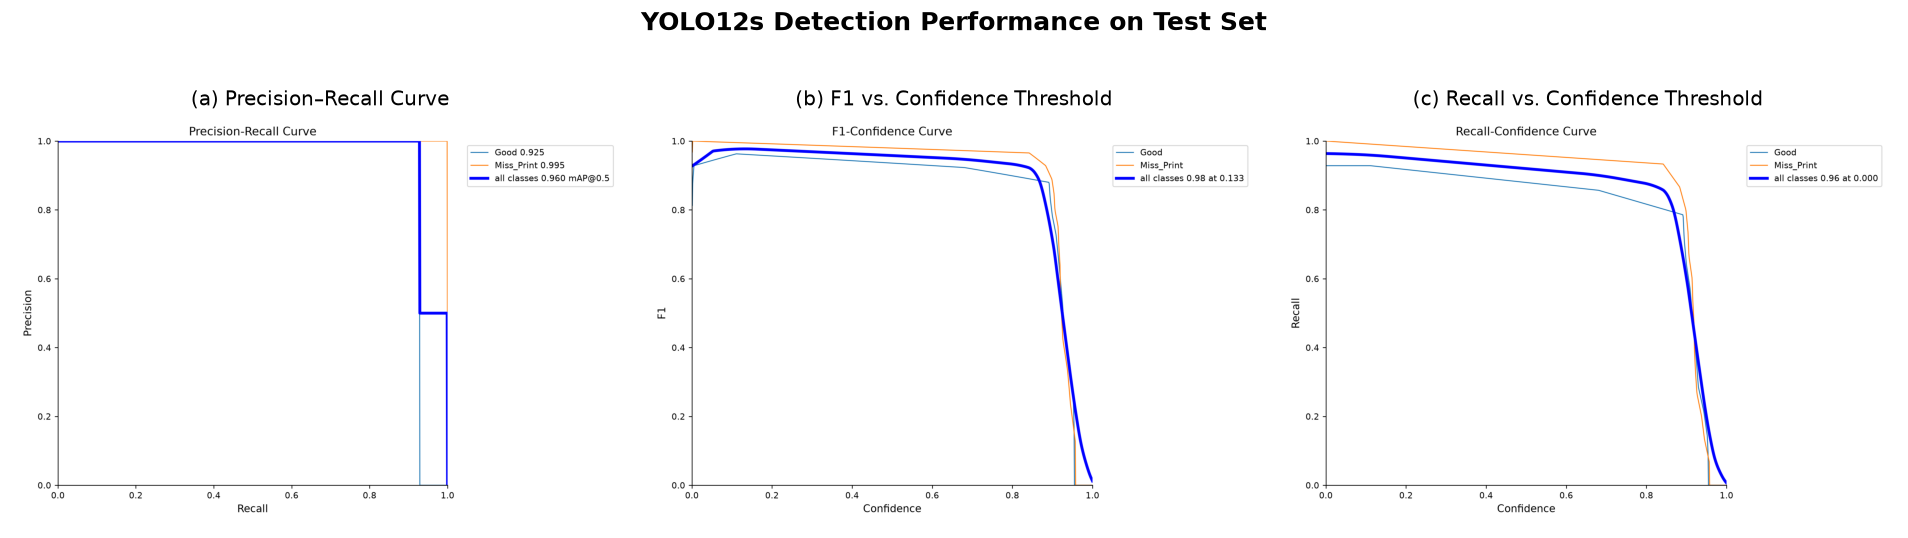


Three-panel visualization generated successfully.
Saved at: G:\Code\object_detection_Project\reports\YOLO12s_curve_analysis


In [23]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURATION
# ============================================================

OUTPUT_DIR = Path(
    r"G:\Code\object_detection_Project\reports\YOLO12s_curve_analysis"
)

# ============================================================
# 1. INSPECT GENERATED FILES
# ============================================================

print("Searching for generated evaluation plots...\n")

for file in OUTPUT_DIR.rglob("*"):
    if file.is_file():
        print(file.relative_to(OUTPUT_DIR))

# ============================================================
# 2. FIND CURVE FILES
# ============================================================

all_pngs = list(OUTPUT_DIR.rglob("*.png"))

def find_curve(candidates):
    for filename in candidates:
        matches = [
            p for p in all_pngs
            if p.name.lower() == filename.lower()
        ]

        if matches:
            return matches[0]

    return None


curve_files = {
    "PR": find_curve([
        "BoxPR_curve.png",
        "PR_curve.png"
    ]),

    "F1": find_curve([
        "BoxF1_curve.png",
        "F1_curve.png"
    ]),

    "Recall": find_curve([
        "BoxR_curve.png",
        "R_curve.png",
        "Recall_curve.png"
    ])
}

# ============================================================
# 3. VALIDATE FILES
# ============================================================

print("\nCurve file detection:")

for name, path in curve_files.items():

    if path is None:
        print(f"[MISSING] {name} curve")
    else:
        print(f"[FOUND] {name}: {path}")

missing = [
    name for name, path in curve_files.items()
    if path is None
]

if missing:
    raise FileNotFoundError(
        f"Missing curves: {missing}. "
        "Check the file listing printed above."
    )

# ============================================================
# 4. CREATE THREE-PANEL FIGURE
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

panel_info = [
    ("PR", "(a) Precision–Recall Curve"),
    ("F1", "(b) F1 vs. Confidence Threshold"),
    ("Recall", "(c) Recall vs. Confidence Threshold")
]

for ax, (key, title) in zip(axes, panel_info):

    image = Image.open(
        curve_files[key]
    ).convert("RGB")

    ax.imshow(image)
    ax.set_title(title, fontsize=12)
    ax.axis("off")

fig.suptitle(
    "YOLO12s Detection Performance on Test Set",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout()

# ============================================================
# 5. SAVE PNG AND PDF
# ============================================================

save_dir = OUTPUT_DIR

fig.savefig(
    save_dir / "YOLO12s_three_panel_curves.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    save_dir / "YOLO12s_three_panel_curves.pdf",
    bbox_inches="tight"
)

plt.show()

print("\nThree-panel visualization generated successfully.")
print("Saved at:", save_dir)
